# Análise Exploratória de Dados (EDA) — AVERITEC-BR

**RES IA ELD UNB — Turma 2 | Grupo 5 |**\
**Challenge 1 — FOMO**

## 1. Contextualização

Esta Análise Exploratória de Dados (EDA) tem como objetivo investigar as principais características estruturais, textuais e de qualidade do conjunto de dados AVERITEC-BR, um dos datasets selecionados pelo grupo durante a etapa de levantamento e avaliação de conjuntos de dados relacionados à desinformação.

O AVERITEC-BR corresponde à versão em português brasileiro do AVeriTeC e contém alegações associadas a quatro classes de veracidade, além de informações relacionadas às evidências utilizadas no processo de verificação. Entre essas informações, o conjunto apresenta uma estrutura de evidências baseada em perguntas e respostas (QA), permitindo explorar não apenas o conteúdo das alegações, mas também os elementos utilizados para sustentá-las ou contestá-las.

A realização da EDA permite compreender como os dados estão organizados, identificar possíveis problemas de qualidade, verificar a distribuição das classes, analisar características dos textos e investigar a estrutura e disponibilidade das evidências.

Essa análise é especialmente relevante para o projeto FOMO, uma vez que a verificação de informações não depende apenas das características linguísticas de uma alegação, mas também da existência, qualidade e relação das evidências disponíveis para sua avaliação.

## 2. Objetivos da análise

A análise exploratória do AVERITEC-BR busca responder às seguintes questões:

- Qual é o tamanho e a estrutura do conjunto de dados?
- Quais variáveis estão disponíveis e como estão organizadas?
- Existem valores ausentes, registros duplicados ou possíveis inconsistências?
- Como as quatro classes de veracidade estão distribuídas?
- A distribuição das classes é semelhante entre os conjuntos de treino e desenvolvimento?
- Quais são as principais características textuais das alegações?
- Qual é o comprimento típico das alegações e existem textos considerados outliers?
- As características superficiais dos textos apresentam diferenças entre as classes?
- Como as evidências estão estruturadas no conjunto de dados?
- Quantas evidências estão associadas a cada alegação?
- Como estão organizadas as perguntas e respostas utilizadas como evidência?
- Existem alegações sem evidências ou com informações de evidência incompletas?
- Quais padrões lexicais e entidades aparecem com maior frequência nas alegações?
- Existem características dos dados que possam representar limitações ou introduzir vieses em etapas posteriores?
- Quais características do AVERITEC-BR podem ser úteis ou representar limitações para o desenvolvimento da FOMO?

A análise será conduzida de forma progressiva, começando pela inspeção dos dados brutos antes de qualquer transformação ou limpeza textual. Essa estratégia permite compreender a estrutura original do dataset, especialmente seus campos aninhados de evidências, antes da preparação dos dados para análises específicas.

In [ ]:
# 2.1. Bibliotecas

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter

# Configurações de visualização
sns.set_theme(style="whitegrid")

# Mostrar todas as colunas dos DataFrames
pd.set_option("display.max_columns", None)

# Permitir visualização de textos maiores
pd.set_option("display.max_colwidth", 200)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 3. Carregamento do conjunto de dados

O AVERITEC-BR utilizado nesta análise é disponibilizado em conjuntos de treino (`train`) e desenvolvimento (`dev`). Antes da realização da EDA, os arquivos serão carregados e sua estrutura será inspecionada.

Nesta etapa, ainda não será realizada limpeza ou transformação dos dados. O objetivo inicial é verificar como os arquivos estão estruturados, confirmar quais variáveis estão efetivamente disponíveis e compreender como as informações relacionadas às alegações e às evidências estão representadas.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dev.json to dev (2).json
Saving train.json to train (2).json


## 4. Inspeção inicial dos arquivos brutos

Antes de converter os dados para uma estrutura tabular, será realizada uma inspeção preliminar dos arquivos para compreender sua organização original.

Como o AVERITEC-BR contém informações relacionadas às alegações e às evidências utilizadas em sua verificação, essa etapa permite identificar possíveis estruturas aninhadas e verificar como os diferentes campos estão representados antes de qualquer transformação dos dados.

In [ ]:
with open("/content/train.json", "r", encoding="utf-8") as f:
    train_raw = json.load(f)

with open("/content/dev.json", "r", encoding="utf-8") as f:
    dev_raw = json.load(f)

print("Tipo do train:", type(train_raw))
print("Tipo do dev:", type(dev_raw))

print("\nQuantidade de registros:")
print("Train:", len(train_raw))
print("Dev:", len(dev_raw))
print("Total:", len(train_raw) + len(dev_raw))

Tipo do train: <class 'list'>
Tipo do dev: <class 'list'>

Quantidade de registros:
Train: 3068
Dev: 500
Total: 3568


#### Resultado da inspeção inicial

Os arquivos carregados apresentam **3.568 registros**, sendo:

- **3.068** registros no conjunto de treino;
- **500** registros no conjunto de desenvolvimento (`dev`).

O número é inferior às **4.568 alegações** atribuídas ao AVeriTeC completo porque os arquivos utilizados nesta análise correspondem aos conjuntos de treino e desenvolvimento. O conjunto original também possui uma partição de teste com **1.000 alegações**, totalizando 4.568 registros.

Dessa forma, a diferença observada não representa perda de registros nos arquivos analisados, mas decorre das partições disponibilizadas e utilizadas nesta EDA.

As análises seguintes serão realizadas sobre os **3.568 registros disponíveis nos conjuntos de treino e desenvolvimento**, mantendo as partições separadas quando necessário.

### 4.1 Estrutura dos registros

Após confirmar a quantidade de registros disponíveis, será analisada a estrutura interna de uma observação do conjunto de treino.

Essa inspeção permite identificar os campos disponíveis, verificar seus tipos e compreender como as informações relacionadas às alegações, rótulos e evidências estão organizadas no arquivo original. Essa etapa é especialmente importante antes da conversão para uma estrutura tabular, pois alguns campos podem apresentar estruturas aninhadas.

In [ ]:
# Inspeção da estrutura do primeiro registro
primeiro_registro = train_raw[0]

print("Campos disponíveis no primeiro registro:\n")

for campo, valor in primeiro_registro.items():
    print(f"{campo}: {type(valor).__name__}")

Campos disponíveis no primeiro registro:

claim: str
required_reannotation: bool
label: str
justification: str
claim_date: str
speaker: str
original_claim_url: NoneType
fact_checking_article: str
reporting_source: str
location_ISO_code: str
claim_types: list
fact_checking_strategies: list
questions: list
cached_original_claim_url: NoneType


### 4.2 Visualização de um registro

Após identificar os campos disponíveis, será visualizado um exemplo completo do conjunto de treino para compreender como essas informações são representadas na prática.

A inspeção será utilizada principalmente para analisar a organização dos campos que apresentam estruturas aninhadas, como `claim_types`, `fact_checking_strategies` e `questions`, antes de qualquer transformação dos dados.

In [ ]:
# Visualizar o primeiro registro de forma organizada
print(json.dumps(
    train_raw[0],
    ensure_ascii=False,
    indent=2
))

{
  "claim": "Hunter Biden não tinha experiência na Ucrânia ou no setor de energia quando se juntou ao conselho da Burisma.",
  "required_reannotation": false,
  "label": "Supported",
  "justification": "Experiência anterior mencionada.",
  "claim_date": "25-8-2020",
  "speaker": "Pam Bondi",
  "original_claim_url": null,
  "fact_checking_article": "https://web.archive.org/web/20210111003633/https://www.politifact.com/article/2020/aug/26/fact-checking-second-night-2020-rnc/",
  "reporting_source": "Speech at The Republican National Convention",
  "location_ISO_code": "US",
  "claim_types": [
    "Position Statement"
  ],
  "fact_checking_strategies": [
    "Written Evidence"
  ],
  "questions": [
    {
      "question": "Hunter Biden teve alguma experiência no setor de energia na época em que ingressou no conselho da empresa de energia Burisma em 2014?",
      "answers": [
        {
          "answer": "Não",
          "answer_type": "Boolean",
          "source_url": "https://en.wikip

## 5. Estrutura geral do conjunto de dados

Após a inspeção dos arquivos brutos, os registros serão organizados em DataFrames para facilitar a análise exploratória.

Os campos aninhados, como `claim_types`, `fact_checking_strategies` e `questions`, serão inicialmente preservados em sua estrutura original. A estrutura de perguntas, respostas e fontes será explorada separadamente em uma etapa posterior, evitando a perda da relação entre as alegações e suas respectivas evidências.

In [ ]:
# Conversão dos registros para DataFrames
train = pd.DataFrame(train_raw)
dev = pd.DataFrame(dev_raw)

print("Dimensão dos conjuntos:")
print(f"Train: {train.shape}")
print(f"Dev:   {dev.shape}")

print("\nColunas disponíveis:")
for i, coluna in enumerate(train.columns, start=1):
    print(f"{i}. {coluna}")

Dimensão dos conjuntos:
Train: (3068, 14)
Dev:   (500, 14)

Colunas disponíveis:
1. claim
2. required_reannotation
3. label
4. justification
5. claim_date
6. speaker
7. original_claim_url
8. fact_checking_article
9. reporting_source
10. location_ISO_code
11. claim_types
12. fact_checking_strategies
13. questions
14. cached_original_claim_url


### 5.1 Consistência estrutural entre os conjuntos

Antes de prosseguir para a análise de qualidade dos dados, será verificado se os conjuntos de treino e desenvolvimento apresentam a mesma estrutura de variáveis.

Essa comparação permite identificar eventuais diferenças entre as partições que poderiam exigir tratamentos distintos durante as etapas seguintes da análise.

In [ ]:
# Comparação das colunas entre os conjuntos
mesmas_colunas = list(train.columns) == list(dev.columns)

print("Train e Dev possuem as mesmas colunas:", mesmas_colunas)

# Comparação dos tipos das variáveis
tipos = pd.DataFrame({
    "train": train.dtypes.astype(str),
    "dev": dev.dtypes.astype(str)
})

tipos["mesmo_tipo"] = tipos["train"] == tipos["dev"]

print("\nTipos das variáveis:")
display(tipos)

Train e Dev possuem as mesmas colunas: True

Tipos das variáveis:


,train,dev,mesmo_tipo
claim,object,object,True
required_reannotation,bool,bool,True
label,object,object,True
justification,object,object,True
claim_date,object,object,True
speaker,object,object,True
original_claim_url,object,object,True
fact_checking_article,object,object,True
reporting_source,object,object,True
location_ISO_code,object,object,True


#### Resultado da análise estrutural

Os conjuntos de treino e desenvolvimento apresentam a mesma estrutura, com **14 variáveis** e tipos de dados compatíveis entre as duas partições.

A variável `required_reannotation` é representada como booleana, enquanto as demais são identificadas pelo pandas como `object`. Nesse grupo estão tanto variáveis textuais quanto campos de estrutura mais complexa, como `claim_types`, `fact_checking_strategies` e `questions`, que armazenam listas e informações aninhadas.

A consistência estrutural entre os conjuntos permite aplicar procedimentos equivalentes de análise nas duas partições. Os campos aninhados serão tratados separadamente nas etapas específicas de análise das evidências.

## 6. Qualidade dos dados

Nesta etapa, serão investigados possíveis problemas de qualidade que possam influenciar as análises posteriores. Serão avaliados valores ausentes, campos vazios, registros duplicados e possíveis inconsistências entre as observações.

Como o AVERITEC-BR contém tanto variáveis textuais quanto campos estruturados em listas, a identificação de ausência de informação não será limitada aos valores reconhecidos automaticamente como nulos pelo pandas. Também serão consideradas strings vazias e listas sem elementos.

### 6.1 Valores ausentes e campos vazios

Inicialmente, será analisada a disponibilidade de informação em cada variável. Para isso, serão considerados como ausentes:

- valores nulos (`None` ou `NaN`);
- strings vazias ou compostas apenas por espaços;
- listas vazias.

A análise será realizada separadamente nos conjuntos de treino e desenvolvimento, permitindo verificar se os padrões de ausência são semelhantes entre as duas partições.

In [ ]:
def identificar_ausencia(valor):
    # None ou NaN
    if valor is None:
        return True

    if isinstance(valor, float) and pd.isna(valor):
        return True

    # Strings vazias
    if isinstance(valor, str) and valor.strip() == "":
        return True

    # Listas vazias
    if isinstance(valor, list) and len(valor) == 0:
        return True

    return False


def resumo_ausencia(df):
    ausentes = df.apply(
        lambda coluna: coluna.map(identificar_ausencia).sum()
    )

    percentual = (ausentes / len(df) * 100).round(2)

    return pd.DataFrame({
        "ausentes": ausentes,
        "percentual": percentual
    })


ausencia_train = resumo_ausencia(train)
ausencia_dev = resumo_ausencia(dev)

print("Valores ausentes — Train")
display(ausencia_train)

print("\nValores ausentes — Dev")
display(ausencia_dev)

Valores ausentes — Train


,ausentes,percentual
claim,1,0.03
required_reannotation,0,0.00
label,0,0.00
justification,0,0.00
claim_date,105,3.42
speaker,695,22.65
original_claim_url,1611,52.51
fact_checking_article,0,0.00
reporting_source,615,20.05
location_ISO_code,336,10.95



Valores ausentes — Dev


,ausentes,percentual
claim,0,0.0
required_reannotation,0,0.0
label,0,0.0
justification,0,0.0
claim_date,0,0.0
speaker,118,23.6
original_claim_url,238,47.6
fact_checking_article,0,0.0
reporting_source,90,18.0
location_ISO_code,50,10.0


#### Resultado da análise de valores ausentes

A análise mostra que os campos centrais do AVERITEC-BR apresentam alta completude. As variáveis `label`, `justification`, `fact_checking_article`, `claim_types`, `fact_checking_strategies` e `questions` não apresentam valores ausentes em nenhuma das duas partições.

No conjunto de treino, foi identificada apenas **uma alegação (`claim`) ausente ou vazia**, correspondente a aproximadamente **0,03%** dos registros. Como a alegação constitui um dos elementos centrais do conjunto de dados, esse registro deverá ser inspecionado individualmente antes de qualquer decisão de tratamento.

As maiores proporções de ausência estão concentradas em campos de metadados. No treino, `cached_original_claim_url` apresenta **62,68%** de ausência e `original_claim_url`, **52,51%**. Também foram observadas ausências em `speaker` (**22,65%**), `reporting_source` (**20,05%**), `location_ISO_code` (**10,95%**) e `claim_date` (**3,42%**).

O conjunto de desenvolvimento apresenta padrão semelhante para vários desses campos: `original_claim_url` possui **47,6%** de ausência, `cached_original_claim_url` **48,4%**, `speaker` **23,6%**, `reporting_source` **18,0%** e `location_ISO_code` **10,0%**. Diferentemente do treino, não foram identificados valores ausentes em `claim_date` ou `claim`.

Apesar da ausência relativamente elevada em alguns metadados, os campos diretamente relacionados à classificação e à estrutura de evidências apresentam elevada completude. Dessa forma, as ausências observadas não possuem necessariamente o mesmo impacto analítico e deverão ser consideradas de acordo com a função de cada variável.

### 6.2 Inspeção de campos centrais ausentes

Como foi identificado um registro do conjunto de treino sem conteúdo no campo `claim`, será realizada uma inspeção específica dessa observação.

O objetivo é verificar se a ausência está restrita ao texto da alegação ou se o registro apresenta outras informações que permitam compreender sua estrutura antes de decidir como tratá-lo nas análises textuais posteriores.

In [ ]:
# Identificar registros sem conteúdo no campo claim
mask_claim_ausente = train["claim"].map(identificar_ausencia)

claim_ausente = train.loc[mask_claim_ausente]

print("Quantidade de registros com claim ausente:", len(claim_ausente))

display(claim_ausente)

Quantidade de registros com claim ausente: 1


,claim,required_reannotation,label,justification,claim_date,speaker,original_claim_url,fact_checking_article,reporting_source,location_ISO_code,claim_types,fact_checking_strategies,questions,cached_original_claim_url
1948,,False,Supported,A afirmação está correta.,8-7-2019,None,None,https://web.archive.org/web/20210720180947/https://dubawa.org/inec-chairmans-claims-whats-true-and-whats-not/,None,NG,[Position Statement],[Written Evidence],"[{'question': 'Alguns países fazem campanha até o dia da eleição?', 'answers': [{'answer': 'Sim', 'answer_type': 'Boolean', 'source_url': 'https://web.archive.org/web/20210720180947/https://www.el...",NaN


#### Resultado da inspeção

O único registro identificado sem conteúdo no campo `claim` corresponde ao índice **1948** do conjunto de treino.

Apesar da ausência do texto da alegação, o registro não está vazio. Ele possui rótulo (`Supported`), justificativa, data, localização, tipo de alegação, estratégia de verificação e informações estruturadas no campo `questions`, incluindo perguntas e respostas utilizadas como evidência.

Portanto, a ausência está restrita ao campo `claim` e não caracteriza a perda completa da observação. O registro será preservado no conjunto de dados para análises que não dependam diretamente do texto da alegação. Nas análises textuais posteriores, que exigem o conteúdo de `claim`, esse registro será desconsiderado.

Essa abordagem evita a exclusão desnecessária de informações válidas presentes nos demais campos do registro.

### 6.3 Registros duplicados

A presença de registros duplicados pode alterar distribuições e atribuir peso excessivo a determinadas observações durante a análise. Por esse motivo, serão investigadas tanto duplicações completas quanto repetições no texto das alegações.

Como o conjunto contém campos estruturados em listas, a verificação de duplicações completas será realizada a partir da representação original dos registros. Em seguida, as alegações (`claim`) serão analisadas separadamente para identificar textos que aparecem mais de uma vez.

In [ ]:
# Verificação de registros completos duplicados
train_serializado = [
    json.dumps(registro, sort_keys=True, ensure_ascii=False)
    for registro in train_raw
]

dev_serializado = [
    json.dumps(registro, sort_keys=True, ensure_ascii=False)
    for registro in dev_raw
]

duplicados_completos_train = pd.Series(train_serializado).duplicated().sum()
duplicados_completos_dev = pd.Series(dev_serializado).duplicated().sum()

print("Registros completos duplicados:")
print("Train:", duplicados_completos_train)
print("Dev:", duplicados_completos_dev)

# Verificação de claims repetidas
claims_duplicadas_train = train[
    train["claim"].notna() &
    train["claim"].astype(str).str.strip().ne("") &
    train["claim"].duplicated(keep=False)
].sort_values("claim")

claims_duplicadas_dev = dev[
    dev["claim"].notna() &
    dev["claim"].astype(str).str.strip().ne("") &
    dev["claim"].duplicated(keep=False)
].sort_values("claim")

print("\nRegistros envolvidos em claims repetidas:")
print("Train:", len(claims_duplicadas_train))
print("Dev:", len(claims_duplicadas_dev))

print("\nNúmero de claims distintas que se repetem:")
print("Train:", claims_duplicadas_train["claim"].nunique())
print("Dev:", claims_duplicadas_dev["claim"].nunique())

Registros completos duplicados:
Train: 0
Dev: 0

Registros envolvidos em claims repetidas:
Train: 139
Dev: 15

Número de claims distintas que se repetem:
Train: 50
Dev: 5


In [ ]:
# Verificar quantos labels diferentes existem para cada claim repetida
labels_por_claim_train = (
    claims_duplicadas_train
    .groupby("claim")["label"]
    .nunique()
    .sort_values(ascending=False)
)

labels_por_claim_dev = (
    claims_duplicadas_dev
    .groupby("claim")["label"]
    .nunique()
    .sort_values(ascending=False)
)

print("Claims repetidas com mais de um label:")
print("Train:", (labels_por_claim_train > 1).sum())
print("Dev:", (labels_por_claim_dev > 1).sum())

print("\nMáximo de labels diferentes para uma mesma claim:")
print("Train:", labels_por_claim_train.max())
print("Dev:", labels_por_claim_dev.max())

Claims repetidas com mais de um label:
Train: 16
Dev: 0

Máximo de labels diferentes para uma mesma claim:
Train: 2
Dev: 1


In [ ]:
# Frequência das claims repetidas
frequencia_train = train["claim"].value_counts()
frequencia_dev = dev["claim"].value_counts()

print("Maior número de ocorrências de uma mesma claim:")
print("Train:", frequencia_train.max())
print("Dev:", frequencia_dev.max())

print("\nDistribuição da frequência das claims repetidas — Train:")
print(frequencia_train[frequencia_train > 1].value_counts().sort_index())

print("\nDistribuição da frequência das claims repetidas — Dev:")
print(frequencia_dev[frequencia_dev > 1].value_counts().sort_index())

Maior número de ocorrências de uma mesma claim:
Train: 7
Dev: 5

Distribuição da frequência das claims repetidas — Train:
count
2    31
3     6
4     8
5     4
7     1
Name: count, dtype: int64

Distribuição da frequência das claims repetidas — Dev:
count
2    3
4    1
5    1
Name: count, dtype: int64


In [ ]:
# Identificar claims do treino associadas a mais de um label
claims_labels_divergentes = labels_por_claim_train[
    labels_por_claim_train > 1
].index

casos_labels_divergentes = (
    train[train["claim"].isin(claims_labels_divergentes)]
    [
        [
            "claim",
            "label",
            "claim_date",
            "speaker",
            "reporting_source",
            "location_ISO_code",
            "fact_checking_article"
        ]
    ]
    .sort_values(["claim", "label"])
)

print(
    "Número de claims repetidas com labels diferentes:",
    len(claims_labels_divergentes)
)

display(casos_labels_divergentes)

Número de claims repetidas com labels diferentes: 16


,claim,label,claim_date,speaker,reporting_source,location_ISO_code,fact_checking_article
2334,"2,5 milhões de passageiros viajaram utilizando o Madaraka Express desde a sua criação em maio de 2018.",Not Enough Evidence,4-4-2019,Kenya President Uhuru Kenyatta,President Republic of Kenya,KE,https://web.archive.org/web/20210719170145/https://africacheck.org/fact-checks/reports/state-nation-2019-did-kenyatta-get-his-facts-right
2354,"2,5 milhões de passageiros viajaram utilizando o Madaraka Express desde a sua criação em maio de 2018.",Supported,4-4-2019,Uhuru Kenyatta,None,KE,https://web.archive.org/web/20210719170145/https://africacheck.org/fact-checks/reports/state-nation-2019-did-kenyatta-get-his-facts-right
1641,A Nigéria tem uma taxa estimada de médico para paciente de um médico para cada 4.000 a 5.000 pacientes.,Not Enough Evidence,10-10-2019,Al Jazeera,News organisation Al Jazeera,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1675,A Nigéria tem uma taxa estimada de médico para paciente de um médico para cada 4.000 a 5.000 pacientes.,Not Enough Evidence,10-10-2019,None,Al Jazeera,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1648,A Nigéria tem uma taxa estimada de médico para paciente de um médico para cada 4.000 a 5.000 pacientes.,Supported,10-10-2019,Socrates Mbamalu,Al Jazeera report,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1664,A Nigéria tem uma taxa estimada de médico para paciente de um médico para cada 4.000 a 5.000 pacientes.,Supported,10-10-2019,Socrates Mbamalu,Al Jazeera,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1680,A Nigéria tem uma taxa estimada de médico para paciente de um médico para cada 4.000 a 5.000 pacientes.,Supported,10-10-2019,Socrates Mbamalu,Al Jazeera,None,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1672,A OMS estima que menos de 10% dos nigerianos com problemas de saúde mental tenham acesso aos cuidados de que necessitam.,Not Enough Evidence,10-10-2019,Al Jazeera,News organisation Al Jazeera,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1659,A OMS estima que menos de 10% dos nigerianos com problemas de saúde mental tenham acesso aos cuidados de que necessitam.,Supported,10-10-2019,Socrates Mbamalu,Al Jazeera,None,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem
1667,A OMS estima que menos de 10% dos nigerianos com problemas de saúde mental tenham acesso aos cuidados de que necessitam.,Supported,10-10-2019,Socrates Mbamalu,Al Jazeera report,NG,https://web.archive.org/web/20210127230319/https://africacheck.org/fact-checks/reports/fact-checked-al-jazeeras-claims-about-nigerias-mental-health-problem


#### Resultado da análise de duplicações

Não foram identificados registros completamente duplicados nos conjuntos de treino ou desenvolvimento.

Entretanto, foram encontradas alegações textualmente repetidas. No conjunto de treino, **139 registros** estão envolvidos em repetições, correspondendo a **50 alegações distintas**. No conjunto de desenvolvimento, foram encontrados **15 registros**, correspondentes a **5 alegações distintas**.

A frequência das repetições também varia. No treino, uma mesma alegação aparece entre duas e sete vezes, enquanto no conjunto de desenvolvimento a maior frequência observada foi de cinco ocorrências.

A análise dos rótulos mostrou que, no conjunto de desenvolvimento, todas as alegações repetidas mantêm o mesmo `label`. No treino, porém, **16 das 50 alegações repetidas estão associadas a dois rótulos diferentes**.

A inspeção desses casos mostra que as repetições não correspondem necessariamente a registros idênticos. Em diferentes ocorrências de uma mesma alegação podem existir variações em campos como `speaker`, `reporting_source`, `claim_date` e outros metadados. Também foram observados casos em que alegações textualmente idênticas, associadas ao mesmo artigo de fact-checking, apresentam rótulos distintos.

Por esse motivo, as repetições não serão removidas automaticamente. Elas serão preservadas durante a EDA, pois podem representar diferentes contextos de verificação ou particularidades do processo de construção e anotação do conjunto de dados.

A presença de textos idênticos associados a rótulos diferentes também indica que o conteúdo textual da alegação, isoladamente, pode não representar toda a informação utilizada no processo de verificação. Essa característica deverá ser considerada especialmente nas análises das evidências e em eventuais etapas posteriores que utilizem apenas o texto da `claim`.

### 6.4 Sobreposição de alegações entre treino e desenvolvimento

Além das repetições internas de cada conjunto, será verificado se existem alegações textualmente idênticas presentes simultaneamente nos conjuntos de treino e desenvolvimento.

Essa análise é relevante porque a presença do mesmo texto em diferentes partições pode influenciar etapas posteriores de avaliação, especialmente em abordagens que utilizem diretamente o conteúdo textual das alegações.

In [ ]:
# Claims válidas em cada conjunto
claims_train = set(
    train.loc[
        train["claim"].notna() & train["claim"].astype(str).str.strip().ne(""),
        "claim"
    ]
)

claims_dev = set(
    dev.loc[
        dev["claim"].notna() & dev["claim"].astype(str).str.strip().ne(""),
        "claim"
    ]
)

# Interseção entre Train e Dev
claims_em_comum = claims_train.intersection(claims_dev)

print("Número de claims distintas presentes em Train e Dev:",
      len(claims_em_comum))

if claims_em_comum:
    sobreposicao = pd.concat([
        train[train["claim"].isin(claims_em_comum)].assign(split="train"),
        dev[dev["claim"].isin(claims_em_comum)].assign(split="dev")
    ])

    display(
        sobreposicao[
            ["split", "claim", "label", "claim_date",
             "speaker", "reporting_source"]
        ].sort_values(["claim", "split"])
    )

Número de claims distintas presentes em Train e Dev: 7


,split,claim,label,claim_date,speaker,reporting_source
214,dev,52% da população atual da Nigéria vive em áreas urbanas.,Supported,1-10-2020,President Muhammadu Buhari,ChannelsTV
215,dev,52% da população atual da Nigéria vive em áreas urbanas.,Supported,1-10-2020,Muhammadu Buhari,Channels Television
216,dev,52% da população atual da Nigéria vive em áreas urbanas.,Supported,1-10-2020,President of Nigeria Muhammadu Buhari,Independence Anniversary Speech
218,dev,52% da população atual da Nigéria vive em áreas urbanas.,Supported,1-10-2020,Muhammadu Buhari,None
1341,train,52% da população atual da Nigéria vive em áreas urbanas.,Supported,19-1-2020,President Muhammadu Buhari,https://www.channelstv.com/2020/10/01/nigeria-at-60-president-buharis-independence-anniversary-speech-full-text/
463,dev,"558 pessoas foram mortas pela polícia em 2018, enquanto 201 pessoas morreram sob custódia policial.",Supported,31-8-2020,None,Instagram
1536,train,"558 pessoas foram mortas pela polícia em 2018, enquanto 201 pessoas morreram sob custódia policial.",Supported,9-11-2019,Paul T Clark,https://africasacountry.com/2019/09/its-time-to-talk-prison-abolition-in-south-africa
458,dev,A Polícia de Segurança Pública da África do Sul mata três vezes mais pessoas por habitante do que a polícia americana.,Not Enough Evidence,31-8-2020,None,Instagram
191,train,A Polícia de Segurança Pública da África do Sul mata três vezes mais pessoas por habitante do que a polícia americana.,Not Enough Evidence,1-8-2020,Cops are Flops,Instagram
565,train,A Polícia de Segurança Pública da África do Sul mata três vezes mais pessoas por habitante do que a polícia americana.,Not Enough Evidence,10-6-2020,Cops are Flops,Facebook


#### Resultado da análise de sobreposição entre as partições

Foram identificadas **7 alegações textualmente idênticas presentes tanto no conjunto de treino quanto no conjunto de desenvolvimento**.

A inspeção desses casos mostra que a sobreposição textual não corresponde necessariamente à repetição completa dos registros. Uma mesma alegação pode estar associada a diferentes datas, autores (`speaker`), fontes de publicação (`reporting_source`) e, em alguns casos, diferentes rótulos.

Há situações em que o rótulo permanece consistente entre as partições, apesar das diferenças de contexto. Entretanto, também foram observados casos em que uma mesma alegação textual aparece associada a rótulos distintos entre registros.

Dessa forma, a presença das mesmas alegações em treino e desenvolvimento deve ser considerada em eventuais etapas posteriores de modelagem e avaliação. Especialmente em abordagens baseadas apenas no texto da `claim`, essa sobreposição indica que o conjunto de desenvolvimento contém textos que também estão presentes no conjunto de treino, aspecto que deverá ser considerado em eventuais etapas posteriores de modelagem e avaliação.

Por outro lado, as diferenças de contexto, metadados e rótulos mostram que a sobreposição textual, isoladamente, não deve ser interpretada automaticamente como duplicação completa ou vazamento de informação. A estrutura das evidências associadas a esses registros também deverá ser considerada.

### 6.5 Registros sinalizados para reanotação

O conjunto de dados contém a variável booleana `required_reannotation`, que permite identificar registros sinalizados para reanotação.

A distribuição desse campo será analisada separadamente nos conjuntos de treino e desenvolvimento para verificar a quantidade e a proporção de observações que apresentam essa indicação.

In [ ]:
# Distribuição de required_reannotation
for nome, df in [("Train", train), ("Dev", dev)]:

    contagem = df["required_reannotation"].value_counts(dropna=False)
    percentual = (
        df["required_reannotation"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    resultado = pd.DataFrame({
        "quantidade": contagem,
        "percentual": percentual
    })

    print(f"{nome}:")
    display(resultado)

Train:


,quantidade,percentual
required_reannotation,,
False,2206,71.9
True,862,28.1


Dev:


,quantidade,percentual
required_reannotation,,
False,378,75.6
True,122,24.4


#### Resultado da análise de reanotação

A variável `required_reannotation` mostra que uma parcela relevante dos registros está sinalizada para reanotação.

No conjunto de treino, **862 registros (28,1%)** apresentam `required_reannotation = True`, enquanto **2.206 (71,9%)** não possuem essa indicação. No conjunto de desenvolvimento, **122 registros (24,4%)** estão sinalizados para reanotação e **378 (75,6%)** não estão.

As proporções são relativamente próximas entre as duas partições, embora a ocorrência seja ligeiramente maior no conjunto de treino.

Como aproximadamente um quarto dos registros analisados apresenta indicação de reanotação, essa variável constitui um aspecto relevante da qualidade do conjunto de dados. Entretanto, a sinalização não será interpretada automaticamente como um erro no registro, uma vez que o campo indica a necessidade de reanotação, mas não informa, isoladamente, qual elemento da observação motivou essa indicação.

Essa característica deverá ser considerada na interpretação das análises seguintes e em eventuais etapas posteriores de preparação dos dados.

### 6.6 Reanotação por classe

Para investigar se a necessidade de reanotação está associada de forma semelhante às diferentes classes do conjunto de dados, será analisada a proporção de registros sinalizados por `label`.

Essa comparação permite verificar se a indicação de reanotação está distribuída entre as classes ou se ocorre com maior frequência em determinados tipos de classificação.

In [ ]:
# Proporção de registros sinalizados para reanotação por classe

for nome, df in [("Train", train), ("Dev", dev)]:

    reanotacao_por_classe = pd.crosstab(
        df["label"],
        df["required_reannotation"],
        normalize="index"
    ).mul(100).round(2)

    reanotacao_por_classe = reanotacao_por_classe.rename(
        columns={
            False: "Não requer reanotação (%)",
            True: "Requer reanotação (%)"
        }
    )

    print(f"{nome}:")
    display(reanotacao_por_classe)

Train:


required_reannotation,Não requer reanotação (%),Requer reanotação (%)
label,,
Conflicting Evidence/Cherrypicking,51.28,48.72
Not Enough Evidence,64.54,35.46
Refuted,75.03,24.97
Supported,72.67,27.33


Dev:


required_reannotation,Não requer reanotação (%),Requer reanotação (%)
label,,
Conflicting Evidence/Cherrypicking,55.26,44.74
Not Enough Evidence,65.71,34.29
Refuted,77.05,22.95
Supported,81.15,18.85


#### Resultado da análise de reanotação por classe

A proporção de registros sinalizados para reanotação apresenta diferenças entre as quatro classes do conjunto de dados.

A classe `Conflicting Evidence/Cherrypicking` apresenta a maior proporção de registros com `required_reannotation = True`, correspondendo a **48,72% no treino** e **44,74% no desenvolvimento**. Em seguida aparece `Not Enough Evidence`, com **35,46%** e **34,29%**, respectivamente.

As classes `Refuted` e `Supported` apresentam proporções menores. Para `Refuted`, **24,97%** dos registros de treino e **22,95%** dos registros de desenvolvimento estão sinalizados. Para `Supported`, os valores correspondem a **27,33% no treino** e **18,85% no desenvolvimento**.

O padrão observado indica que a sinalização para reanotação não está distribuída de maneira uniforme entre as classes. Além disso, a maior ocorrência nas classes `Conflicting Evidence/Cherrypicking` e `Not Enough Evidence` aparece tanto no conjunto de treino quanto no de desenvolvimento.

A análise, entretanto, não permite determinar apenas a partir dessa variável por que determinados registros foram sinalizados. Portanto, os resultados indicam uma associação entre a classe e a necessidade de reanotação, mas não estabelecem uma relação causal.

## 7. Distribuição das classes

Após a análise da qualidade dos dados, será investigada a distribuição da variável alvo (`label`).

O AVERITEC-BR utiliza quatro classes de veracidade:

- `Supported`;
- `Refuted`;
- `Not Enough Evidence`;
- `Conflicting Evidence/Cherrypicking`.

A análise da frequência absoluta e relativa dessas classes permite verificar o grau de equilíbrio do conjunto de dados e identificar possíveis diferenças de distribuição entre as partições de treino e desenvolvimento.

### 7.1 Frequência das classes

Inicialmente, serão calculadas a quantidade e a proporção de registros pertencentes a cada classe nos conjuntos de treino e desenvolvimento.

In [ ]:
def distribuicao_classes(df):
    contagem = df["label"].value_counts()
    percentual = (
        df["label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    return pd.DataFrame({
        "quantidade": contagem,
        "percentual": percentual
    })


distribuicao_train = distribuicao_classes(train)
distribuicao_dev = distribuicao_classes(dev)

print("Distribuição das classes — Train")
display(distribuicao_train)

print("\nDistribuição das classes — Dev")
display(distribuicao_dev)

Distribuição das classes — Train


,quantidade,percentual
label,,
Refuted,1742,56.78
Supported,849,27.67
Not Enough Evidence,282,9.19
Conflicting Evidence/Cherrypicking,195,6.36



Distribuição das classes — Dev


,quantidade,percentual
label,,
Refuted,305,61.0
Supported,122,24.4
Conflicting Evidence/Cherrypicking,38,7.6
Not Enough Evidence,35,7.0


#### Resultado da distribuição das classes

A distribuição da variável `label` mostra que as quatro classes não possuem a mesma representatividade no conjunto de dados.

No conjunto de treino, `Refuted` é a classe mais frequente, com **1.742 registros (56,78%)**, seguida por `Supported`, com **849 registros (27,67%)**. As classes `Not Enough Evidence` e `Conflicting Evidence/Cherrypicking` apresentam menor representação, correspondendo a **9,19%** e **6,36%** dos registros, respectivamente.

O conjunto de desenvolvimento apresenta padrão semelhante. A classe `Refuted` representa **61,0%** dos registros e `Supported`, **24,4%**. As classes menos frequentes são `Conflicting Evidence/Cherrypicking`, com **7,6%**, e `Not Enough Evidence`, com **7,0%**.

Embora existam pequenas diferenças nas proporções entre as partições, ambas apresentam predominância de `Refuted`, seguida por `Supported`, enquanto as duas classes restantes possuem participação consideravelmente menor.

Essa distribuição caracteriza um **desequilíbrio entre as classes**, aspecto relevante para a interpretação do conjunto e para eventuais etapas posteriores de modelagem e avaliação, uma vez que as classes menos representadas fornecem menor quantidade de exemplos.

### 7.2 Visualização da distribuição das classes

Para facilitar a comparação entre as partições, será utilizada uma visualização da distribuição percentual das quatro classes nos conjuntos de treino e desenvolvimento.

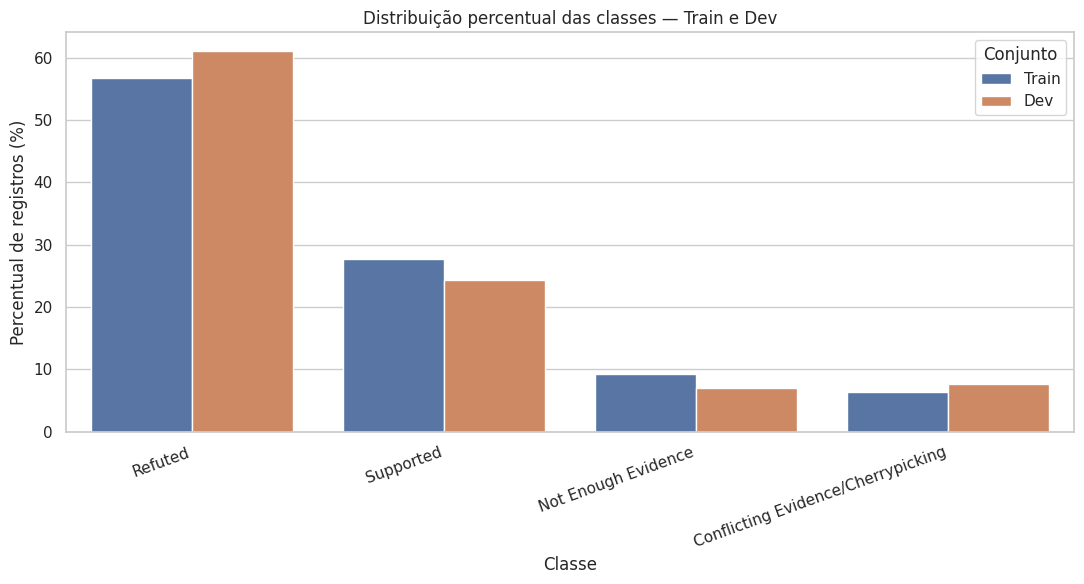

In [ ]:
# Preparar dados para visualização
dist_train_plot = (
    train["label"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentual")
    .reset_index()
)

dist_train_plot["split"] = "Train"

dist_dev_plot = (
    dev["label"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentual")
    .reset_index()
)

dist_dev_plot["split"] = "Dev"

dist_plot = pd.concat(
    [dist_train_plot, dist_dev_plot],
    ignore_index=True
)

# Gráfico
plt.figure(figsize=(11, 6))

sns.barplot(
    data=dist_plot,
    x="label",
    y="percentual",
    hue="split"
)

plt.title("Distribuição percentual das classes — Train e Dev")
plt.xlabel("Classe")
plt.ylabel("Percentual de registros (%)")

plt.xticks(rotation=20, ha="right")
plt.legend(title="Conjunto")
plt.tight_layout()
plt.show()

#### Interpretação da distribuição das classes

A visualização confirma o desequilíbrio observado numericamente entre as quatro classes do AVERITEC-BR.

Em ambas as partições, `Refuted` concentra mais da metade dos registros, enquanto `Supported` representa aproximadamente um quarto do conjunto. As classes `Not Enough Evidence` e `Conflicting Evidence/Cherrypicking` apresentam participação consideravelmente menor.

Apesar de pequenas variações percentuais, os conjuntos de treino e desenvolvimento apresentam um padrão geral semelhante de distribuição. A principal diferença ocorre entre as classes menos frequentes: `Not Enough Evidence` possui maior participação no treino, enquanto `Conflicting Evidence/Cherrypicking` apresenta proporção ligeiramente maior no desenvolvimento.

A predominância das duas primeiras classes e a menor disponibilidade de exemplos das demais devem ser consideradas em etapas posteriores, especialmente na escolha de métricas de avaliação e na interpretação do desempenho por classe.

## 8. Características textuais das alegações

Além da estrutura e da distribuição das classes, é importante compreender as características dos textos presentes na variável `claim`.

Nesta etapa, as alegações serão analisadas em sua forma original, antes da aplicação de procedimentos de limpeza textual. Serão avaliados aspectos como comprimento em caracteres e palavras, medidas descritivas, distribuição dos comprimentos e presença de valores extremos.

Como foi identificado anteriormente um registro do conjunto de treino sem conteúdo na variável `claim`, esse registro será preservado no conjunto original, mas excluído especificamente das análises que dependem do conteúdo textual.

### 8.1 Preparação da base para análise textual

Para as análises textuais, serão criadas cópias auxiliares dos conjuntos contendo apenas registros com alegações disponíveis.

Também serão criadas duas variáveis derivadas:

- `num_caracteres`: quantidade de caracteres da alegação;
- `num_palavras`: quantidade de palavras da alegação.

Essas variáveis permitem descrever e visualizar a extensão dos textos sem modificar o conteúdo original das alegações.

In [ ]:
# Criar bases auxiliares apenas com claims disponíveis
train_texto = train[
    train["claim"].notna() &
    train["claim"].astype(str).str.strip().ne("")
].copy()

dev_texto = dev[
    dev["claim"].notna() &
    dev["claim"].astype(str).str.strip().ne("")
].copy()

# Criar variáveis de comprimento
for df in [train_texto, dev_texto]:
    df["num_caracteres"] = df["claim"].str.len()
    df["num_palavras"] = df["claim"].str.split().str.len()

print("Registros utilizados na análise textual:")
print(f"Train: {len(train_texto)} de {len(train)}")
print(f"Dev:   {len(dev_texto)} de {len(dev)}")

print("\nEstatísticas — Train")
display(
    train_texto[["num_caracteres", "num_palavras"]]
    .describe()
    .round(2)
)

print("\nEstatísticas — Dev")
display(
    dev_texto[["num_caracteres", "num_palavras"]]
    .describe()
    .round(2)
)

Registros utilizados na análise textual:
Train: 3067 de 3068
Dev:   500 de 500

Estatísticas — Train


,num_caracteres,num_palavras
count,3067.00,3067.00
mean,114.28,18.81
std,55.56,9.09
min,16.00,3.00
25%,76.00,13.00
50%,103.00,17.00
75%,140.50,23.00
max,453.00,73.00



Estatísticas — Dev


,num_caracteres,num_palavras
count,500.00,500.00
mean,117.65,19.34
std,53.80,8.76
min,20.00,4.00
25%,78.00,13.00
50%,108.00,18.00
75%,151.00,25.00
max,427.00,72.00


#### Resultado da análise do comprimento das alegações

Para a análise textual, foram utilizados **3.067 dos 3.068 registros de treino**, uma vez que o registro anteriormente identificado sem conteúdo em `claim` foi excluído apenas desta etapa. Todos os **500 registros de desenvolvimento** possuem alegações disponíveis.

No conjunto de treino, as alegações apresentam em média **114,28 caracteres** e **18,81 palavras**, com medianas de **103 caracteres** e **17 palavras**. No conjunto de desenvolvimento, as médias são de **117,65 caracteres** e **19,34 palavras**, com medianas de **108 caracteres** e **18 palavras**.

As medidas são semelhantes entre as duas partições, indicando que treino e desenvolvimento apresentam características próximas quanto à extensão das alegações.

Em ambos os conjuntos, a média do número de palavras é ligeiramente superior à mediana, enquanto os valores máximos chegam a **73 palavras no treino** e **72 palavras no desenvolvimento**. Esses resultados indicam a presença de alegações mais extensas na parte superior da distribuição.

No treino, 50% das alegações possuem entre **13 e 23 palavras**, enquanto no desenvolvimento esse intervalo varia de **13 a 25 palavras**. A presença de valores máximos consideravelmente superiores ao terceiro quartil justifica uma análise específica da distribuição e de possíveis valores extremos.

### 8.2 Identificação de valores extremos

As estatísticas descritivas mostraram que algumas alegações apresentam comprimento consideravelmente superior ao valor típico observado no conjunto de treino.

Para investigar esses casos de forma objetiva, será utilizado o intervalo interquartil (IQR). Serão considerados valores extremos superiores os registros cujo número de palavras ultrapasse o limite definido por:

**Q3 + 1,5 × IQR**

A identificação desses registros não implica sua remoção automática. Os textos serão posteriormente inspecionados para verificar se representam erros, problemas estruturais ou apenas variações legítimas no comprimento das alegações.

In [ ]:
# Cálculo do IQR para o número de palavras — Train

q1 = train_texto["num_palavras"].quantile(0.25)
q3 = train_texto["num_palavras"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_superiores = train_texto[
    train_texto["num_palavras"] > limite_superior
].copy()

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

print(f"\nAlegações acima do limite superior: {len(outliers_superiores)}")

percentual_outliers = (
    len(outliers_superiores) / len(train_texto) * 100
)

print(f"Percentual do conjunto: {percentual_outliers:.2f}%")

Q1: 13.00
Q3: 23.00
IQR: 10.00
Limite inferior: -2.00
Limite superior: 38.00

Alegações acima do limite superior: 113
Percentual do conjunto: 3.68%


#### Resultado da identificação de valores extremos

As alegações do conjunto de treino apresentam **mediana de 17 palavras**, indicando que aproximadamente metade dos textos possui até 17 palavras e metade possui 17 palavras ou mais. Além disso, 50% das alegações estão concentradas entre **13 palavras (Q1)** e **23 palavras (Q3)**.

A partir desses quartis, foi obtido um **IQR de 10 palavras**. A aplicação do critério de 1,5 × IQR resultou em um limite superior de **38 palavras** para a identificação de valores extremos.

Foram encontradas **113 alegações acima desse limite**, correspondendo a **3,68% dos registros utilizados na análise textual**. Dessa forma, embora o comprimento típico das alegações esteja próximo de 17 palavras, existe uma pequena parcela de textos consideravelmente mais extensos.

O limite inferior calculado pelo método foi de -2 palavras. Como o comprimento de um texto não pode assumir valores negativos e a menor alegação observada possui três palavras, não foram identificados valores extremos inferiores por esse critério.

A classificação estatística dessas 113 alegações como valores extremos não significa que elas sejam necessariamente erros. Textos mais extensos podem representar variações legítimas do conjunto de dados. Por esse motivo, os registros de maior comprimento serão inspecionados antes de qualquer decisão sobre sua qualidade ou eventual tratamento.

### 8.3 Inspeção das alegações mais longas

Após a identificação estatística dos valores extremos, serão inspecionadas as alegações de maior comprimento.

O objetivo é verificar se os textos mais extensos apresentam indícios de problemas estruturais, como conteúdo concatenado, repetições ou outros padrões incomuns, ou se correspondem a alegações válidas naturalmente mais longas.

Essa inspeção é importante porque a identificação de um valor extremo pelo IQR não implica, por si só, um problema de qualidade nos dados.

In [ ]:
# 10 alegações mais longas do conjunto de treino

claims_mais_longas = (
    train_texto[
        [
            "claim",
            "num_palavras",
            "num_caracteres",
            "label",
            "required_reannotation"
        ]
    ]
    .sort_values("num_palavras", ascending=False)
    .head(10)
)

display(claims_mais_longas)

,claim,num_palavras,num_caracteres,label,required_reannotation
1047,"F. Scott Fitzgerald escreveu uma carta durante a pandemia da Gripe Espanhola de 1920, na qual escreveu para alguém chamada “Rosemary”, na qual escreveu: “Até os bares, como eu contei a Hemingway, ...",73,418,Refuted,True
1776,"Donald Trump ameaçou sanções econômicas devido à violência xenófoba recente na África do Sul com um tuíte publicado afirmando: “Esses ataques bárbaros do sul-africano são muito decepcionantes, é h...",70,453,Refuted,False
2296,"William Shakespeare escreveu: ""Eu sempre me sinto feliz, você sabe por quê? Porque eu não espero nada de ninguém. As expectativas sempre machucam. A vida é curta, então ame sua vida, seja feliz. E...",70,413,Refuted,False
112,Máscaras médicas para o rosto são projetadas para serem usadas de forma diferente dependendo da saúde do usuário. A máscara deve ser usada com o lado colorido para fora se você estiver doente e nã...,70,382,Not Enough Evidence,True
528,Sarah Huckabee Sanders publicou um tweet conspiratório e alegou que é “curioso” que a insurgência da ANITFA tenha ocorrido justamente quando a COVID-19 perdeu força. É “curioso” que a COVID-19 ten...,64,409,Refuted,True
776,"O cronograma do governo irlandês para flexibilizar as restrições da Covid-19 será apresentado em 5 fases. Essas fases terão um processo de revisão de 3 semanas, e as fases atuais começarão nas seg...",64,313,Supported,False
2509,"Para muitos, muitas décadas, os veteranos têm tentado conseguir o VA Choice. Você não conseguia. ... Agora, esses grandes veteranos, se houver uma longa espera, eles vão a um médico local. Nós pag...",64,384,Refuted,True
578,"O Governo de Assam anuncia: ""Entrada gratuita de 100% para estudantes em faculdades até o nível de pós-graduação. Nenhuma faculdade poderá cobrar nada de nenhum estudante. Não serão cobradas taxas...",61,399,Supported,True
607,"Milhares de prisões foram feitas nos EUA para tráfico de crianças, tráfico humano e abuso sexual, mas a mídia não está relatando isso. Enfermeiras estão vindo à tona, falando publicamente sobre o ...",61,395,Not Enough Evidence,True
2876,"O CEO do Kansas City Chiefs, Clark Hunt, disse: ""Você permanecerá em pé, com a mão sobre o coração e com respeito, quando nosso hino nacional estiver sendo tocado, ou você não será mais um Kansas ...",61,353,Refuted,False


### 8.4 Comprimento das alegações e reanotação

A inspeção das alegações mais longas mostrou que parte desses registros também está sinalizada para reanotação.

Para verificar se esse padrão se estende além dos casos extremos, será comparado o comprimento das alegações entre registros com e sem `required_reannotation`, além da proporção de reanotação entre as alegações identificadas como valores extremos pelo IQR.

In [ ]:
# Comprimento textual segundo required_reannotation
comparacao_reanotacao = (
    train_texto
    .groupby("required_reannotation")["num_palavras"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print("Comprimento das alegações por status de reanotação:")
display(comparacao_reanotacao)

# Proporção de reanotação entre os outliers de comprimento
taxa_outliers = (
    outliers_superiores["required_reannotation"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nReanotação entre as 113 alegações acima de 38 palavras:")
display(taxa_outliers)

Comprimento das alegações por status de reanotação:


,count,mean,median,std
required_reannotation,,,,
False,2205,18.52,17.0,8.80
True,862,19.56,18.0,9.77



Reanotação entre as 113 alegações acima de 38 palavras:


,proportion
required_reannotation,
False,59.29
True,40.71


#### Resultado da comparação entre comprimento e reanotação

Os registros sinalizados para reanotação apresentam alegações ligeiramente mais longas, em média, do que os registros não sinalizados.

Entre os registros com `required_reannotation = False`, o comprimento médio é de **18,52 palavras**, com mediana de **17 palavras**. Entre aqueles com `required_reannotation = True`, a média aumenta para **19,56 palavras** e a mediana para **18 palavras**.

Embora exista diferença, os valores centrais permanecem próximos, indicando que o comprimento textual, isoladamente, não separa claramente os dois grupos.

Entre as **113 alegações com mais de 38 palavras**, identificadas anteriormente como valores extremos pelo critério do IQR, **40,71%** estão sinalizadas para reanotação. Essa proporção é superior aos **28,1% observados no conjunto de treino completo**.

O resultado indica uma associação descritiva entre alegações de comprimento extremo e maior presença da sinalização para reanotação. Entretanto, essa comparação não permite concluir que o maior comprimento seja responsável pela necessidade de reanotação, uma vez que outros aspectos do conteúdo, das evidências ou do processo de anotação podem estar relacionados à variável.

### 8.5 Comprimento das alegações por classe

Para investigar se existem diferenças superficiais na extensão dos textos entre as classes, será comparado o número de palavras das alegações de acordo com o `label`.

Essa análise permite verificar se determinadas classes apresentam textos tipicamente mais longos ou mais curtos. Diferenças desse tipo podem representar padrões do próprio conjunto de dados que devem ser considerados na interpretação de análises posteriores.

In [ ]:
# Estatísticas do número de palavras por classe

comprimento_por_classe = (
    train_texto
    .groupby("label")["num_palavras"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
    .round(2)
    .sort_values("mediana")
)

display(comprimento_por_classe)

,quantidade,media,mediana,desvio_padrao,minimo,maximo
label,,,,,,
Conflicting Evidence/Cherrypicking,195,17.75,16.0,8.48,3,47
Refuted,1742,18.60,17.0,9.37,3,73
Supported,848,19.07,18.0,8.37,4,64
Not Enough Evidence,282,20.06,19.0,9.70,4,70


#### Resultado da análise do comprimento por classe

As quatro classes apresentam diferenças moderadas no comprimento das alegações, embora os valores centrais permaneçam relativamente próximos.

A classe `Conflicting Evidence/Cherrypicking` apresenta as alegações mais curtas, com média de **17,75 palavras** e mediana de **16 palavras**. Em seguida aparecem `Refuted`, com média de **18,60** e mediana de **17 palavras**, e `Supported`, com média de **19,07** e mediana de **18 palavras**.

A classe `Not Enough Evidence` apresenta os maiores valores, com média de **20,06 palavras** e mediana de **19 palavras**.

Apesar dessa progressão, a diferença entre as medianas das classes é de apenas três palavras, e todas apresentam dispersão considerável, com desvios-padrão entre **8,37 e 9,70 palavras**. Portanto, o comprimento das alegações apresenta alguma variação entre as classes, mas não evidencia, isoladamente, uma separação clara entre os rótulos.

Os maiores valores também aparecem em diferentes classes, indicando que a presença de alegações extensas não está restrita a uma única categoria.

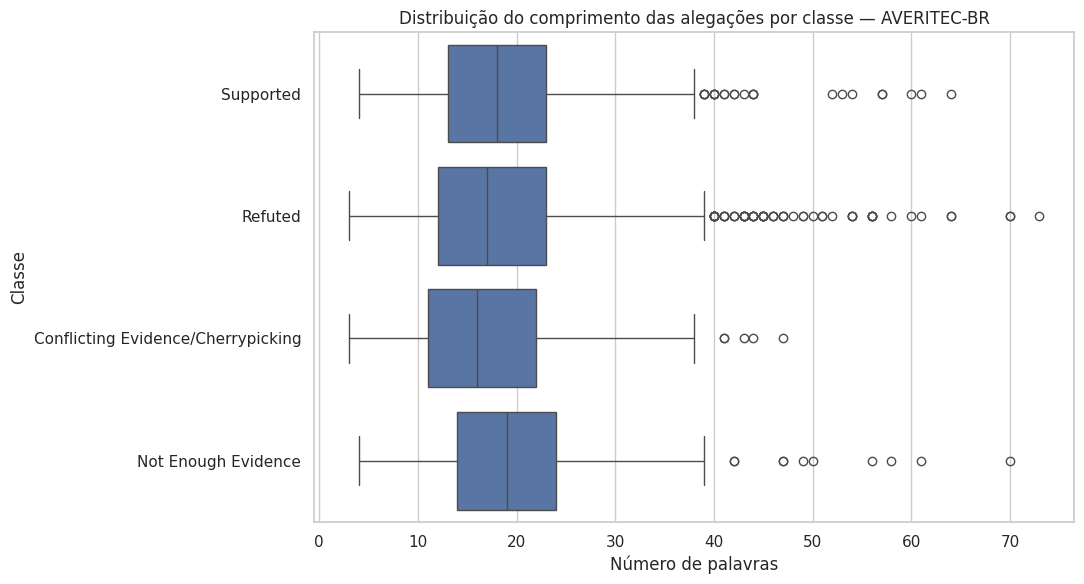

In [ ]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=train_texto,
    x="num_palavras",
    y="label"
)

plt.title("Distribuição do comprimento das alegações por classe — AVERITEC-BR")
plt.xlabel("Número de palavras")
plt.ylabel("Classe")

plt.tight_layout()
plt.show()

#### Visualização do comprimento das alegações por classe

O boxplot mostra que as distribuições do número de palavras apresentam **forte sobreposição entre as quatro classes**, sem uma separação evidente dos rótulos com base apenas no comprimento das alegações.

As medianas são próximas entre as classes, embora `Not Enough Evidence` apresente uma tendência a alegações ligeiramente mais extensas, enquanto `Conflicting Evidence/Cherrypicking` apresenta valores centrais um pouco menores.

Também são observados valores atípicos de comprimento em todas as classes. A classe `Refuted`, além de ser a mais frequente no conjunto, apresenta maior quantidade visual de observações acima dos limites do boxplot e inclui algumas das alegações mais extensas.

Esses resultados reforçam que o comprimento da alegação é útil para caracterizar o conjunto, mas **não apresenta, isoladamente, um padrão claramente discriminativo entre os rótulos**. Além disso, os valores identificados como atípicos pelo boxplot não devem ser considerados automaticamente como erros, pois alegações extensas podem representar registros legítimos.

## 9. Estrutura das evidências

Uma das principais características do AVERITEC-BR é a presença de informações estruturadas relacionadas às evidências utilizadas na verificação das alegações.

Essas informações estão armazenadas no campo `questions`, que possui uma estrutura aninhada. Cada alegação pode conter uma ou mais perguntas de verificação e, para cada pergunta, podem existir uma ou mais respostas associadas a fontes de evidência.

Antes de transformar essa estrutura em tabelas auxiliares, será realizada uma inspeção de sua organização para identificar os campos disponíveis e possíveis variações entre os registros.

### 9.1 Inspeção da estrutura de perguntas e respostas

Inicialmente, serão identificadas as chaves presentes nos objetos de perguntas e respostas ao longo dos conjuntos de treino e desenvolvimento.

Essa verificação permite confirmar se a estrutura das evidências é uniforme ou se existem diferentes formatos que precisam ser considerados antes da análise.

In [ ]:
# Identificar as diferentes chaves presentes em questions e answers

chaves_questions = set()
chaves_answers = set()

tipos_questions = set()
tipos_answers = set()

for df in [train, dev]:
    for questions in df["questions"]:

        tipos_questions.add(type(questions).__name__)

        if isinstance(questions, list):
            for question in questions:

                if isinstance(question, dict):
                    chaves_questions.update(question.keys())

                    answers = question.get("answers", [])
                    tipos_answers.add(type(answers).__name__)

                    if isinstance(answers, list):
                        for answer in answers:
                            if isinstance(answer, dict):
                                chaves_answers.update(answer.keys())

print("Tipos encontrados em 'questions':")
print(tipos_questions)

print("\nChaves encontradas nos objetos de pergunta:")
print(sorted(chaves_questions))

print("\nTipos encontrados em 'answers':")
print(tipos_answers)

print("\nChaves encontradas nos objetos de resposta:")
print(sorted(chaves_answers))

Tipos encontrados em 'questions':
{'list'}

Chaves encontradas nos objetos de pergunta:
['answers', 'question']

Tipos encontrados em 'answers':
{'list'}

Chaves encontradas nos objetos de resposta:
['answer', 'answer_type', 'boolean_explanation', 'cached_source_url', 'source_medium', 'source_url']


#### Resultado da inspeção da estrutura das evidências

A inspeção dos campos aninhados mostrou uma estrutura consistente para as evidências nos conjuntos de treino e desenvolvimento.

O campo `questions` é representado por uma lista, cujos elementos possuem duas chaves:

- `question`: pergunta utilizada durante o processo de verificação;
- `answers`: lista contendo as respostas associadas à pergunta.

Os objetos presentes em `answers` também seguem uma estrutura comum, composta pelos campos:

- `answer`;
- `answer_type`;
- `boolean_explanation`;
- `cached_source_url`;
- `source_medium`;
- `source_url`.

Essa organização confirma uma estrutura hierárquica do tipo **alegação → pergunta → resposta/evidência**. Como o formato encontrado é consistente, as informações poderão ser organizadas em tabelas auxiliares para permitir análises quantitativas sem alterar a estrutura original do conjunto de dados.

### 9.2 Quantidade de perguntas e respostas por alegação

A quantidade de perguntas e respostas associadas a cada alegação será analisada para compreender o volume de informações utilizadas na estrutura de evidências.

Serão calculados, para cada registro:

- número de perguntas de verificação;
- número total de respostas associadas às perguntas.

Essa análise permite verificar se todas as alegações possuem evidências estruturadas e identificar diferenças na quantidade de informações disponíveis entre os registros.

In [ ]:
# Contar perguntas e respostas por alegação

def contar_evidencias(df):
    resultado = df.copy()

    resultado["num_perguntas"] = resultado["questions"].apply(
        lambda questions: len(questions)
    )

    resultado["num_respostas"] = resultado["questions"].apply(
        lambda questions: sum(
            len(question.get("answers", []))
            for question in questions
            if isinstance(question, dict)
        )
    )

    return resultado


train_evidencias = contar_evidencias(train)
dev_evidencias = contar_evidencias(dev)


for nome, df in [
    ("Train", train_evidencias),
    ("Dev", dev_evidencias)
]:

    print(f"\n{nome} — Número de perguntas por alegação")
    display(
        df["num_perguntas"]
        .describe()
        .round(2)
        .to_frame()
    )

    print(f"{nome} — Número de respostas por alegação")
    display(
        df["num_respostas"]
        .describe()
        .round(2)
        .to_frame()
    )


Train — Número de perguntas por alegação


,num_perguntas
count,3068.00
mean,2.60
std,1.57
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,16.00


Train — Número de respostas por alegação


,num_respostas
count,3068.00
mean,2.76
std,1.73
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,16.00



Dev — Número de perguntas por alegação


,num_perguntas
count,500.00
mean,2.57
std,1.54
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,12.00


Dev — Número de respostas por alegação


,num_respostas
count,500.00
mean,2.80
std,1.81
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,16.00


#### Resultado da quantidade de perguntas e respostas

A estrutura de evidências apresenta comportamento bastante semelhante entre os conjuntos de treino e desenvolvimento.

No conjunto de treino, cada alegação possui, em média, **2,60 perguntas**, com mediana de **2 perguntas**. Metade dos registros apresenta entre **2 e 3 perguntas**, enquanto o número máximo observado é de **16 perguntas**.

No conjunto de desenvolvimento, a média é de **2,57 perguntas**, também com mediana de **2** e intervalo interquartil entre **2 e 3 perguntas**. O maior valor observado nessa partição é de **12 perguntas**.

A quantidade de respostas apresenta comportamento semelhante. No treino, existem em média **2,76 respostas por alegação**, com mediana de **2 respostas**, enquanto no desenvolvimento a média é de **2,80**, também com mediana de **2 respostas**. Em ambas as partições, 50% dos registros apresentam entre **2 e 3 respostas**.

O número mínimo observado é de uma pergunta e uma resposta por alegação em ambas as partições. Portanto, embora a análise inicial de valores ausentes já tivesse mostrado que nenhuma lista `questions` estava completamente vazia, esta etapa permite confirmar também que todos os registros analisados possuem pelo menos uma resposta associada à sua estrutura de evidências.

Os valores máximos, que chegam a **16 perguntas ou respostas**, mostram que algumas alegações possuem estruturas de verificação consideravelmente mais extensas do que o padrão observado no conjunto.

### 9.3 Número de respostas associadas a cada pergunta

Na análise anterior, a quantidade de perguntas e respostas foi calculada no nível da alegação. Nesta etapa, a unidade de análise passa a ser cada pergunta individual.

O objetivo é verificar quantas respostas estão associadas a uma mesma pergunta de verificação, permitindo identificar se o padrão predominante é de uma única resposta por pergunta ou se são frequentes os casos em que uma pergunta utiliza múltiplas respostas como evidência.

In [ ]:
# Criar tabela auxiliar no nível das perguntas

registros_perguntas = []

for nome_split, df in [("Train", train), ("Dev", dev)]:

    for indice, row in df.iterrows():

        for numero_pergunta, question in enumerate(
            row["questions"], start=1
        ):

            registros_perguntas.append({
                "split": nome_split,
                "claim_index": indice,
                "label": row["label"],
                "numero_pergunta": numero_pergunta,
                "question": question.get("question"),
                "num_respostas": len(question.get("answers", []))
            })

perguntas_df = pd.DataFrame(registros_perguntas)

print("Total de perguntas:", len(perguntas_df))

print("\nQuantidade de respostas por pergunta:")
display(
    perguntas_df["num_respostas"]
    .value_counts()
    .sort_index()
    .rename_axis("número de respostas")
    .to_frame("quantidade de perguntas")
)

print("\nEstatísticas:")
display(
    perguntas_df["num_respostas"]
    .describe()
    .round(2)
    .to_frame()
)

Total de perguntas: 9272

Quantidade de respostas por pergunta:


,quantidade de perguntas
número de respostas,
1,8734
2,472
3,64
4,2



Estatísticas:


,num_respostas
count,9272.00
mean,1.07
std,0.28
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,4.00


#### Resultado da análise de respostas por pergunta

Foram identificadas **9.272 perguntas** nos conjuntos de treino e desenvolvimento.

A estrutura predominante é de **uma resposta para cada pergunta**: 8.734 perguntas apresentam exatamente uma resposta. Em comparação, 472 perguntas possuem duas respostas, 64 possuem três e apenas 2 perguntas apresentam quatro respostas.

A mediana e os três quartis são iguais a uma resposta, reforçando que a utilização de múltiplas respostas para uma mesma pergunta representa uma parcela minoritária da estrutura de evidências.

Também não foram identificadas perguntas sem resposta. Portanto, todas as perguntas presentes nos registros analisados possuem pelo menos uma resposta associada.

Esse resultado mostra que, embora uma alegação possa possuir várias perguntas de verificação, cada pergunta é normalmente sustentada por uma única resposta, existindo apenas uma pequena parcela de casos com múltiplas respostas.

### 9.4 Tipos de resposta

Além da quantidade de evidências disponíveis, é importante compreender como as respostas associadas às perguntas de verificação estão estruturadas.

O campo `answer_type` indica o tipo de resposta registrada para cada evidência. Nesta etapa, serão identificadas as categorias existentes e suas respectivas frequências.

A análise será realizada no nível das respostas, preservando a relação de cada evidência com sua alegação, pergunta, classe e partição de origem.

In [ ]:
# Criar tabela auxiliar no nível das respostas

registros_respostas = []

for nome_split, df in [("Train", train), ("Dev", dev)]:

    for indice, row in df.iterrows():

        for numero_pergunta, question in enumerate(
            row["questions"], start=1
        ):

            for numero_resposta, answer in enumerate(
                question.get("answers", []), start=1
            ):

                registros_respostas.append({
                    "split": nome_split,
                    "claim_index": indice,
                    "label": row["label"],
                    "numero_pergunta": numero_pergunta,
                    "numero_resposta": numero_resposta,
                    "question": question.get("question"),
                    "answer": answer.get("answer"),
                    "answer_type": answer.get("answer_type"),
                    "source_url": answer.get("source_url"),
                    "source_medium": answer.get("source_medium"),
                    "boolean_explanation": answer.get("boolean_explanation"),
                    "cached_source_url": answer.get("cached_source_url")
                })

respostas_df = pd.DataFrame(registros_respostas)

print("Total de respostas:", len(respostas_df))

print("\nTipos de resposta:")
display(
    respostas_df["answer_type"]
    .value_counts(dropna=False)
    .rename_axis("answer_type")
    .to_frame("quantidade")
)

print("\nTipos de resposta (%):")
display(
    respostas_df["answer_type"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
    .rename_axis("answer_type")
    .to_frame("percentual")
)

Total de respostas: 9878

Tipos de resposta:


,quantidade
answer_type,
Extractive,5278
Abstractive,2586
Boolean,1589
Unanswerable,425



Tipos de resposta (%):


,percentual
answer_type,
Extractive,53.43
Abstractive,26.18
Boolean,16.09
Unanswerable,4.30


#### Resultado da análise dos tipos de resposta

Foram identificadas **9.878 respostas** associadas às perguntas de verificação nos conjuntos de treino e desenvolvimento.

O tipo mais frequente é `Extractive`, com **5.278 respostas (53,43%)**, representando pouco mais da metade das evidências. Em seguida aparece `Abstractive`, com **2.586 respostas (26,18%)**.

As respostas do tipo `Boolean` correspondem a **1.589 ocorrências (16,09%)**, enquanto `Unanswerable` é a categoria menos frequente, com **425 respostas (4,30%)**.

A distribuição mostra que a estrutura de evidências do AVERITEC-BR não utiliza um único formato de resposta. Embora respostas extrativas sejam predominantes, aproximadamente metade das ocorrências está distribuída entre respostas abstrativas, booleanas e não respondíveis.

Essa diversidade é uma característica relevante do conjunto de dados, pois indica que as evidências associadas às alegações podem assumir diferentes formas de representação e não devem ser tratadas como um único tipo de conteúdo textual.

### 9.5 Inspeção dos diferentes tipos de resposta

Após identificar quatro categorias no campo `answer_type`, serão inspecionados exemplos de cada tipo.

O objetivo é observar como os campos `answer` e `boolean_explanation` são utilizados em cada categoria e verificar se existem diferenças estruturais relevantes entre os tipos de resposta.

In [ ]:
# Exemplos de cada tipo de resposta

for tipo in respostas_df["answer_type"].dropna().unique():

    print("\n" + "=" * 80)
    print(f"ANSWER_TYPE: {tipo}")
    print("=" * 80)

    exemplos = (
        respostas_df[
            respostas_df["answer_type"] == tipo
        ][
            [
                "question",
                "answer",
                "boolean_explanation"
            ]
        ]
        .head(3)
    )

    display(exemplos)


ANSWER_TYPE: Boolean


,question,answer,boolean_explanation
0,Hunter Biden teve alguma experiência no setor de energia na época em que ingressou no conselho da empresa de energia Burisma em 2014?,Não,A história profissional anterior de Hunter Biden não inclui trabalho para empresas de energia.
1,Hunter Biden teve alguma experiência na Ucrânia na época em que se juntou ao conselho da empresa de energia Burisma em 2014?,Não,O histórico profissional anterior de Hunter Biden não inclui trabalho com empresas ucranianas.
18,Joe Biden apoiou o voto a favor da guerra na Síria?,Sim,Ele votou a favor da guerra na Sérvia com a Resolução do Kosovo.



ANSWER_TYPE: Abstractive


,question,answer,boolean_explanation
2,A proposta de lei tributária de 2017 entregou os maiores cortes de impostos da história americana?,Esta redução de impostos é a 8ª maior em percentagem do Produto Interno Bruto (PIB) desde 1918 e a 4ª maior em dólares ajustados pela inflação.,None
3,Houve contas de impostos maiores que a conta de impostos de 2017?,"Três projetos de lei tributária foram maiores: Lei de Alívio Tributário para o American Taxpayer (aprovada em 2013); Lei de Alívio Tributário, Reautorização do Seguro de Desemprego e Criação de Em...",None
22,Quanto da receita da Nigéria vai para o governo federal?,"52,68 % vai para o governo federal.",None



ANSWER_TYPE: Extractive


,question,answer,boolean_explanation
4,"Odinga, ex-primeiro-ministro do Quênia, confunde seus números sobre a participação do governo na receita do Nigéria?","A Nigéria, ele disse, tem um sistema de governo local, estadual e federal. ""Em termos de compartilhamento de receita, 20% da receita vai para o governo local, 35% vai para o governo estadual e 45%...",None
5,"Quando Joe Biden participou de uma entrevista com a Associação Nacional de Jornalistas Negros e a Associação Nacional de Jornalistas Hispanicos, em 6 de agosto de 2020, ele disse que derrubaria a ...","Não, não haverá mais um metro de muro construído durante minha administração... Eu vou garantir que tenhamos proteção de fronteira, mas ela será baseada em garantir que usemos capacidade de alta t...",None
6,"Se Joe Biden se tornasse presidente, qual é a sua intenção em relação à saúde para imigrantes ilegais?","Assim, a tarefa de trabalho recomenda permitir que imigrantes aqui ilegalmente tenham acesso a cuidados de saúde, incluindo cobertura da Lei de Cuidados Acessíveis. Mas ser capaz de comprar seguro...",None



ANSWER_TYPE: Unanswerable


,question,answer,boolean_explanation
59,Quantos juízes estavam em Kenia em 2020?,Nenhuma resposta foi encontrada.,None
60,Quantos magistrados havia no Quênia em 2020?,Nenhuma resposta foi encontrada.,None
61,Existe uma média global para o número de juízes em relação à população?,Nenhuma resposta foi encontrada.,None


#### Resultado da inspeção dos tipos de resposta

A inspeção dos exemplos confirma que os quatro valores de `answer_type` correspondem a diferentes formas de representação das respostas utilizadas na estrutura de evidências.

Nas respostas do tipo `Boolean`, o campo `answer` apresenta uma resposta direta, como “Sim” ou “Não”, enquanto o campo `boolean_explanation` fornece uma justificativa textual adicional.

As respostas `Abstractive` apresentam uma formulação textual sintética da informação utilizada para responder à pergunta. Nos exemplos inspecionados, o campo `boolean_explanation` não é utilizado nesse tipo de resposta.

As respostas `Extractive`, por sua vez, apresentam trechos textuais mais extensos associados à pergunta de verificação. Assim como nas respostas abstrativas observadas, o campo `boolean_explanation` não é utilizado nos exemplos desse tipo.

Por fim, as respostas classificadas como `Unanswerable` indicam situações em que não foi encontrada uma resposta para a pergunta formulada. Nos exemplos inspecionados, o campo `answer` registra explicitamente “Nenhuma resposta foi encontrada”.

Esses resultados mostram que os campos internos das evidências possuem funções diferentes de acordo com o tipo de resposta. Por esse motivo, a presença ou ausência de valores em campos como `boolean_explanation` não deve ser interpretada automaticamente como um problema de qualidade sem considerar o respectivo `answer_type`.

### 9.6 Completude dos campos das respostas

Como os diferentes tipos de resposta utilizam os campos da estrutura de evidências de formas distintas, a análise de valores ausentes será realizada considerando o `answer_type`.

O objetivo é distinguir ausências esperadas pela própria estrutura do dado de possíveis lacunas nas evidências, especialmente nos campos `answer`, `boolean_explanation`, `source_url`, `source_medium` e `cached_source_url`.

In [ ]:
# Função para identificar valores ausentes em campos das respostas

def esta_ausente(valor):
    if valor is None:
        return True

    if isinstance(valor, float) and pd.isna(valor):
        return True

    if isinstance(valor, str) and valor.strip() == "":
        return True

    return False


campos_resposta = [
    "answer",
    "boolean_explanation",
    "source_url",
    "source_medium",
    "cached_source_url"
]

# Percentual de ausência por answer_type
ausencia_por_tipo = {}

for tipo, grupo in respostas_df.groupby("answer_type"):

    ausencia_por_tipo[tipo] = {
        campo: round(
            grupo[campo].apply(esta_ausente).mean() * 100,
            2
        )
        for campo in campos_resposta
    }

ausencia_por_tipo_df = pd.DataFrame(ausencia_por_tipo).T

ausencia_por_tipo_df.index.name = "answer_type"

display(ausencia_por_tipo_df)

,answer,boolean_explanation,source_url,source_medium,cached_source_url
answer_type,,,,,
Abstractive,0.00,100.0,0.00,0.00,17.56
Boolean,0.00,0.0,0.06,0.06,14.29
Extractive,0.02,100.0,0.00,0.00,17.73
Unanswerable,0.00,100.0,100.00,100.00,100.00


#### Resultado da análise de completude das respostas

A análise condicionada ao `answer_type` mostra que grande parte das ausências observadas nos campos das respostas é compatível com a própria estrutura dos diferentes tipos de evidência.

Nas respostas `Abstractive`, os campos `answer`, `source_url` e `source_medium` estão completamente preenchidos, enquanto `boolean_explanation` está ausente em 100% dos casos. O mesmo padrão de ausência desse campo ocorre nas respostas `Extractive`, nas quais `answer`, `source_url` e `source_medium` também apresentam preenchimento praticamente completo.

Nas respostas `Boolean`, o campo `boolean_explanation` está preenchido em todos os registros, confirmando sua utilização específica para fornecer a justificativa textual de respostas booleanas. Foram observadas apenas ausências residuais de **0,06%** em `source_url` e `source_medium`.

As respostas `Unanswerable` apresentam um comportamento distinto. Embora o campo `answer` esteja preenchido, `source_url`, `source_medium` e `cached_source_url` estão ausentes em 100% desses registros. Esse padrão é coerente com a própria categoria, que representa perguntas para as quais nenhuma resposta foi encontrada.

O campo `cached_source_url` apresenta maior proporção de ausência também entre os tipos respondíveis, variando de aproximadamente **14% a 18%**. Como o campo corresponde a uma versão armazenada da fonte, sua ausência deve ser distinguida da ausência de `source_url`, que permanece praticamente completa nas respostas em que uma evidência foi encontrada.

Como exceções pontuais, foi identificado apenas **um registro `Extractive` sem conteúdo no campo `answer`**, apesar de possuir `source_url` e `source_medium`, e **um registro `Boolean` sem `source_url` e `source_medium`**, embora apresente resposta e justificativa textual.

De forma geral, a estrutura principal das respostas apresenta elevada completude. As ausências observadas estão concentradas principalmente em campos cuja utilização depende do tipo de resposta, enquanto as inconsistências encontradas em campos normalmente preenchidos são casos isolados. Assim, os resultados não indicam um problema estrutural generalizado de completude nas evidências.

### 9.7 Inspeção de ausências inesperadas nas evidências

Embora a maior parte dos valores ausentes seja compatível com a estrutura dos diferentes tipos de resposta, foram identificadas pequenas exceções em campos que normalmente estão preenchidos.

Esses casos serão inspecionados individualmente para verificar se representam problemas de qualidade, particularidades da anotação ou outras situações específicas do conjunto de dados.

In [ ]:
# Extractive sem conteúdo em answer
extractive_sem_answer = respostas_df[
    (respostas_df["answer_type"] == "Extractive") &
    (respostas_df["answer"].apply(esta_ausente))
]

print("Extractive sem answer:", len(extractive_sem_answer))

display(
    extractive_sem_answer[
        [
            "split",
            "claim_index",
            "label",
            "question",
            "answer",
            "source_url",
            "source_medium"
        ]
    ]
)


# Boolean com ausência em source_url ou source_medium
boolean_sem_fonte = respostas_df[
    (respostas_df["answer_type"] == "Boolean") &
    (
        respostas_df["source_url"].apply(esta_ausente) |
        respostas_df["source_medium"].apply(esta_ausente)
    )
]

print("\nBoolean com source_url ou source_medium ausente:",
      len(boolean_sem_fonte))

display(
    boolean_sem_fonte[
        [
            "split",
            "claim_index",
            "label",
            "question",
            "answer",
            "boolean_explanation",
            "source_url",
            "source_medium"
        ]
    ]
)

Extractive sem answer: 1


,split,claim_index,label,question,answer,source_url,source_medium
5773,Train,2106,Conflicting Evidence/Cherrypicking,O que o governo nigeriano fez sobre os desafios de segurança?,,https://www.e-ir.info/2013/11/06/the-responses-of-the-nigerian-defense-and-intelligence-establishments-to-the-boko-haram-security-challenge/,Web text



Boolean com source_url ou source_medium ausente: 1


,split,claim_index,label,question,answer,boolean_explanation,source_url,source_medium
3189,Train,1175,Refuted,Temperaturas acima de 56 graus Celsius matam o coronavírus?,Não,"Não há pesquisa, exceto por informações sobre o coronavírus SARS de 2002-2003.",,


#### Resultado da inspeção das ausências inesperadas

A inspeção confirmou que as ausências inesperadas identificadas na análise de completude correspondem a apenas **dois casos isolados**, ambos presentes no conjunto de treino.

Entre as respostas `Extractive`, foi identificado **um único registro sem conteúdo no campo `answer`**. Apesar dessa ausência, o registro possui `source_url` e `source_medium` preenchidos, indicando que existe uma fonte de evidência associada à pergunta.

Entre as respostas `Boolean`, também foi identificado **um único registro sem `source_url` e `source_medium`**. Nesse caso, entretanto, os campos `answer` e `boolean_explanation` estão preenchidos, preservando tanto a resposta booleana quanto sua justificativa textual.

Dessa forma, as ausências inesperadas representam ocorrências pontuais, e não um padrão recorrente de incompletude na estrutura das evidências. Como os dois registros ainda preservam informações relevantes, eles serão mantidos nesta etapa exploratória.

### 9.8 Meios das fontes de evidência

Além do tipo de resposta, o AVERITEC-BR informa o meio associado às fontes utilizadas como evidência por meio do campo `source_medium`.

Nesta etapa, será analisada a distribuição desses meios para identificar quais tipos de fonte aparecem com maior frequência na estrutura de evidências.

As respostas classificadas como `Unanswerable` serão desconsideradas nesta análise, uma vez que não possuem fonte associada.

In [ ]:
# Distribuição dos meios das fontes de evidência

fontes_com_evidencia = respostas_df[
    respostas_df["answer_type"] != "Unanswerable"
].copy()

distribuicao_medium = (
    fontes_com_evidencia["source_medium"]
    .value_counts(dropna=False)
    .to_frame("quantidade")
)

distribuicao_medium["percentual"] = (
    distribuicao_medium["quantidade"]
    / len(fontes_com_evidencia)
    * 100
).round(2)

display(distribuicao_medium)

,quantidade,percentual
source_medium,,
Web text,6842,72.38
PDF,1112,11.76
Metadata,599,6.34
Web table,423,4.47
Image/graphic,219,2.32
Other,132,1.40
Video,122,1.29
Audio,3,0.03
,1,0.01


#### Resultado da análise dos meios das fontes de evidência

A análise do campo `source_medium` mostra predominância de fontes classificadas como **`Web text`**, que representam **72,38%** das respostas com evidência associada. Esse resultado indica que a maior parte das evidências do AVERITEC-BR é proveniente de conteúdo textual disponível na web.

O segundo meio mais frequente é `PDF`, responsável por **11,76%** das evidências, seguido por `Metadata` (**6,34%**) e `Web table` (**4,47%**). Outras modalidades aparecem com menor frequência, incluindo `Image/graphic` (**2,32%**), `Other` (**1,40%**), `Video` (**1,29%**) e `Audio` (**0,03%**).

Apesar da predominância de conteúdo textual da web, a presença de PDFs, tabelas, imagens, vídeos, áudios e metadados mostra que a estrutura de evidências não está restrita a um único formato de informação.

Também foi identificado **um único registro com o valor `1` no campo `source_medium`**, correspondendo a aproximadamente **0,01%** das respostas analisadas. Como esse valor difere das demais categorias observadas, o registro será inspecionado individualmente antes de ser interpretado como uma possível inconsistência de anotação.

In [ ]:
# Verificar exatamente quais valores existem em source_medium

print(
    fontes_com_evidencia["source_medium"]
    .value_counts(dropna=False)
)

source_medium
Web text         6842
PDF              1112
Metadata          599
Web table         423
Image/graphic     219
Other             132
Video             122
Audio               3
                    1
Name: count, dtype: int64


#### Resultado da análise dos meios das fontes de evidência

A análise do campo `source_medium` mostra predominância de fontes classificadas como **`Web text`**, que representam **72,38%** das respostas com evidência associada. Esse resultado indica que a maior parte das evidências do AVERITEC-BR é proveniente de conteúdo textual disponível na web.

O segundo meio mais frequente é `PDF`, responsável por **11,76%** das evidências, seguido por `Metadata` (**6,34%**) e `Web table` (**4,47%**). Outras modalidades aparecem com menor frequência, incluindo `Image/graphic` (**2,32%**), `Other` (**1,40%**), `Video` (**1,29%**) e `Audio` (**0,03%**).

Apesar da predominância de conteúdo textual da web, a presença de PDFs, tabelas, imagens, vídeos, áudios e metadados mostra que a estrutura de evidências contempla diferentes formatos de informação.

Também foi identificado **um único registro com `source_medium` vazio**, correspondendo a aproximadamente **0,01%** das respostas analisadas. Trata-se de uma ocorrência isolada em comparação com o preenchimento praticamente completo desse campo observado anteriormente.

In [ ]:
# Inspeção do registro com source_medium vazio

medium_vazio = respostas_df[
    respostas_df["source_medium"].apply(esta_ausente) &
    (respostas_df["answer_type"] != "Unanswerable")
]

display(
    medium_vazio[
        [
            "split",
            "claim_index",
            "label",
            "question",
            "answer",
            "answer_type",
            "boolean_explanation",
            "source_url",
            "source_medium"
        ]
    ]
)

,split,claim_index,label,question,answer,answer_type,boolean_explanation,source_url,source_medium
3189,Train,1175,Refuted,Temperaturas acima de 56 graus Celsius matam o coronavírus?,Não,Boolean,"Não há pesquisa, exceto por informações sobre o coronavírus SARS de 2002-2003.",,


#### Resultado da análise dos meios das fontes de evidência

A análise do campo `source_medium` mostra predominância de fontes classificadas como **`Web text`**, que representam **72,38%** das respostas com evidência associada. Esse resultado indica que a maior parte das evidências do AVERITEC-BR é proveniente de conteúdo textual disponível na web.

O segundo meio mais frequente é `PDF`, responsável por **11,76%** das evidências, seguido por `Metadata` (**6,34%**) e `Web table` (**4,47%**). Outras modalidades aparecem com menor frequência, incluindo `Image/graphic` (**2,32%**), `Other` (**1,40%**), `Video` (**1,29%**) e `Audio` (**0,03%**).

Apesar da predominância de conteúdo textual da web, a presença de PDFs, tabelas, imagens, vídeos, áudios e metadados mostra que a estrutura de evidências contempla diferentes formatos de informação.

Foi identificado apenas **um registro com `source_medium` vazio**, correspondendo a aproximadamente **0,01%** das respostas analisadas. A inspeção confirmou que se trata do mesmo registro `Boolean` já identificado na análise de completude das evidências, que também não possui `source_url`, mas mantém preenchidos os campos `answer` e `boolean_explanation`.

Dessa forma, além da forte concentração em evidências textuais provenientes da web, o conjunto apresenta diversidade de meios e elevado preenchimento do campo `source_medium`, com apenas uma ausência pontual entre as respostas em que uma evidência foi encontrada.

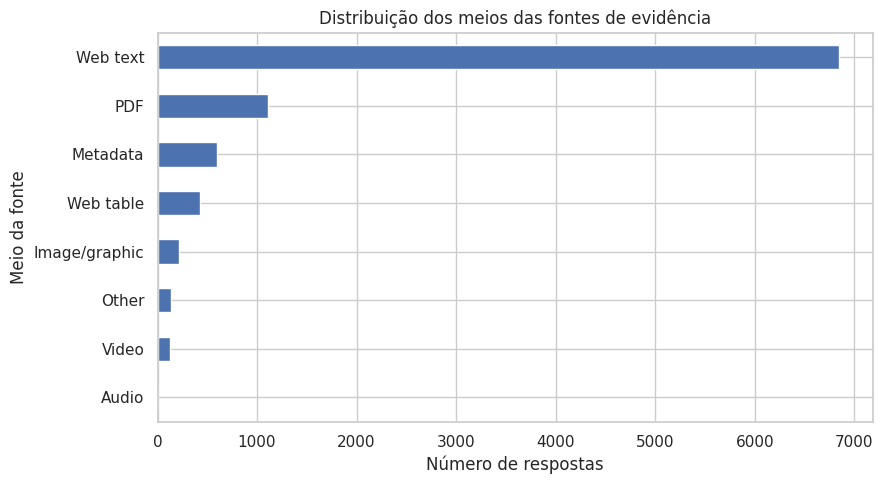

In [ ]:
# Distribuição dos meios das fontes de evidência

medium_plot = (
    fontes_com_evidencia[
        ~fontes_com_evidencia["source_medium"].apply(esta_ausente)
    ]["source_medium"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

medium_plot.plot(kind="barh")

plt.title("Distribuição dos meios das fontes de evidência")
plt.xlabel("Número de respostas")
plt.ylabel("Meio da fonte")

plt.tight_layout()
plt.show()

### 9.9 Domínios das fontes de evidência

Além do meio utilizado como fonte, é relevante investigar a origem das evidências disponíveis no conjunto de dados.

Nesta etapa, serão extraídos os domínios presentes em `source_url` para identificar quais fontes aparecem com maior frequência e verificar se existe concentração das evidências em determinados sites.

Essa análise considera a frequência de utilização dos domínios nas respostas, portanto um mesmo domínio pode aparecer diversas vezes associado a diferentes evidências.

In [ ]:
# Extração dos domínios das fontes

from urllib.parse import urlparse

def extrair_dominio(url):
    if esta_ausente(url):
        return np.nan

    try:
        dominio = urlparse(str(url)).netloc.lower()

        # Remove "www."
        if dominio.startswith("www."):
            dominio = dominio[4:]

        return dominio if dominio else np.nan

    except:
        return np.nan


respostas_df["source_domain"] = respostas_df["source_url"].apply(extrair_dominio)

# Quantidade de domínios identificados
print("Respostas com domínio identificado:",
      respostas_df["source_domain"].notna().sum())

print("Domínios distintos:",
      respostas_df["source_domain"].nunique())

print("\n20 domínios mais frequentes:")

top_dominios = respostas_df["source_domain"].value_counts().head(20)

display(top_dominios.to_frame("quantidade"))

Respostas com domínio identificado: 8826
Domínios distintos: 1879

20 domínios mais frequentes:


,quantidade
source_domain,
web.archive.org,3526
twitter.com,206
africacheck.org,108
en.wikipedia.org,105
who.int,69
facebook.com,68
archive.ph,60
edition.cnn.com,50
cdc.gov,50


#### Resultado inicial da análise dos domínios

Foram identificadas **8.826 respostas com um domínio extraível em `source_url`**, distribuídas entre **1.879 domínios distintos**, indicando ampla diversidade de endereços utilizados na estrutura de evidências.

Entretanto, o domínio mais frequente foi `web.archive.org`, presente em **3.526 respostas**, número muito superior ao dos demais domínios. Essa frequência deve ser interpretada com cautela, pois o endereço corresponde a um serviço de arquivamento de páginas da web e pode representar versões preservadas de conteúdos originalmente publicados em diferentes sites.

Entre os demais domínios aparecem plataformas de redes sociais, organizações de checagem, instituições de saúde, veículos jornalísticos e outras fontes, como `twitter.com`, `africacheck.org`, `who.int`, `facebook.com`, `cdc.gov`, `reuters.com` e `bbc.co.uk`.

Dessa forma, a contagem direta de `source_url` permite observar a diversidade das evidências, mas a elevada presença de URLs arquivadas pode ocultar parte da distribuição das fontes originais. Antes de interpretar a concentração por domínio ou produzir uma visualização, é necessário verificar se os endereços do `web.archive.org` permitem recuperar o domínio original das páginas arquivadas.

In [ ]:
# Inspeção de exemplos de URLs do web.archive.org

urls_archive = (
    respostas_df.loc[
        respostas_df["source_domain"] == "web.archive.org",
        "source_url"
    ]
    .dropna()
    .drop_duplicates()
)

print("URLs distintas do web.archive.org:", len(urls_archive))
print("\nExemplos:\n")

for url in urls_archive.head(10):
    print(url)
    print()

URLs distintas do web.archive.org: 2539

Exemplos:

https://web.archive.org/web/20210307003741/https://www.youtube.com/watch?v=w5x3rmkrDOE&feature=youtu.be&t=1204

https://web.archive.org/web/20200908054813/https://consortiumofnlus.ac.in/documents/Notification_August_25_2020.pdf

https://web.archive.org/web/20200929223259/https://www.neiti.gov.ng/index.php/revenue-allocation

https://web.archive.org/web/20201209174955/https://www.congress.gov/bill/107th-congress/house-joint-resolution/114/actions

https://web.archive.org/web/20201210005946/https://www.govtrack.us/congress/votes/106-1999/s57

https://web.archive.org/web/20201223161307/https://www.politico.com/story/2016/06/joe-biden-libya-wrong-224595

https://web.archive.org/web/20210111011501/https://joebiden.com/gunsafety/

https://web.archive.org/web/20210113224448/https://www.usatoday.com/story/opinion/2020/06/10/biden-root-out-systemic-racism-not-just-divisive-trump-talk-column/5327631002/

https://web.archive.org/web/202105100640

#### Recuperação dos domínios originais de páginas arquivadas

A inspeção das URLs associadas ao `web.archive.org` mostrou que os endereços preservam a URL original da página arquivada.

Dessa forma, considerar diretamente `web.archive.org` como domínio da evidência poderia superestimar a participação do serviço de arquivamento e ocultar as fontes originais utilizadas no conjunto de dados.

Para obter uma representação mais adequada da origem das evidências, os domínios originais presentes nas URLs arquivadas serão recuperados antes da análise de frequência.

In [ ]:
# Recuperação do domínio original das URLs arquivadas

def extrair_dominio_original(url):
    if esta_ausente(url):
        return np.nan

    url = str(url).strip()

    try:
        dominio = urlparse(url).netloc.lower()

        if dominio.startswith("www."):
            dominio = dominio[4:]

        # URLs armazenadas no Internet Archive
        if dominio == "web.archive.org":
            match = re.search(
                r"/web/(?:\d+|\*)/(https?://.+)",
                url
            )

            if match:
                url_original = match.group(1)
                dominio_original = urlparse(url_original).netloc.lower()

                if dominio_original.startswith("www."):
                    dominio_original = dominio_original[4:]

                return dominio_original if dominio_original else dominio

        return dominio if dominio else np.nan

    except:
        return np.nan


respostas_df["source_domain_original"] = (
    respostas_df["source_url"]
    .apply(extrair_dominio_original)
)

print(
    "Respostas com domínio identificado:",
    respostas_df["source_domain_original"].notna().sum()
)

print(
    "Domínios distintos:",
    respostas_df["source_domain_original"].nunique()
)

print("\n20 domínios mais frequentes após recuperação das URLs arquivadas:\n")

top_dominios_originais = (
    respostas_df["source_domain_original"]
    .value_counts()
    .head(20)
)

display(
    top_dominios_originais.to_frame("quantidade")
)

Respostas com domínio identificado: 8826
Domínios distintos: 2453

20 domínios mais frequentes após recuperação das URLs arquivadas:



,quantidade
source_domain_original,
twitter.com,309
africacheck.org,256
web.archive.org,176
who.int,137
cdc.gov,127
en.wikipedia.org,111
facebook.com,102
nytimes.com,96
washingtonpost.com,77


#### Resultado da análise dos domínios das fontes

Inicialmente, foram identificadas **8.826 respostas com domínio extraível em `source_url`**, distribuídas entre **1.879 domínios distintos**. Entretanto, `web.archive.org` aparecia como o domínio mais frequente, com 3.526 ocorrências.

A inspeção dessas URLs mostrou que grande parte dos endereços do Internet Archive preservava a URL original da página arquivada. Por esse motivo, os domínios originais foram recuperados sempre que possível, evitando interpretar o serviço de arquivamento como a própria fonte da evidência.

Após esse tratamento, permaneceram **8.826 respostas com domínio identificado**, mas o número de domínios distintos aumentou para **2.453**, revelando uma diversidade de fontes maior do que aquela observada diretamente nas URLs brutas.

Os domínios mais frequentes passaram a ser `twitter.com` (309 ocorrências), `africacheck.org` (256), `who.int` (137), `cdc.gov` (127), `en.wikipedia.org` (111) e `facebook.com` (102). Entre os demais domínios mais frequentes também aparecem veículos jornalísticos, plataformas digitais, organizações de checagem e instituições públicas ou científicas.

O domínio `web.archive.org` ainda permaneceu em **176 ocorrências** após o tratamento. Esses casos podem corresponder a formatos de URL nos quais o domínio original não foi recuperado pela regra utilizada, devendo essa limitação ser considerada na interpretação dos resultados.

De forma geral, a análise mostra que as evidências estão distribuídas entre um grande número de domínios e não concentradas em uma única fonte. Ao mesmo tempo, a presença de diferentes tipos de origem — como redes sociais, veículos jornalísticos, organizações de checagem, instituições governamentais e fontes científicas — evidencia a heterogeneidade das fontes utilizadas no conjunto de dados.

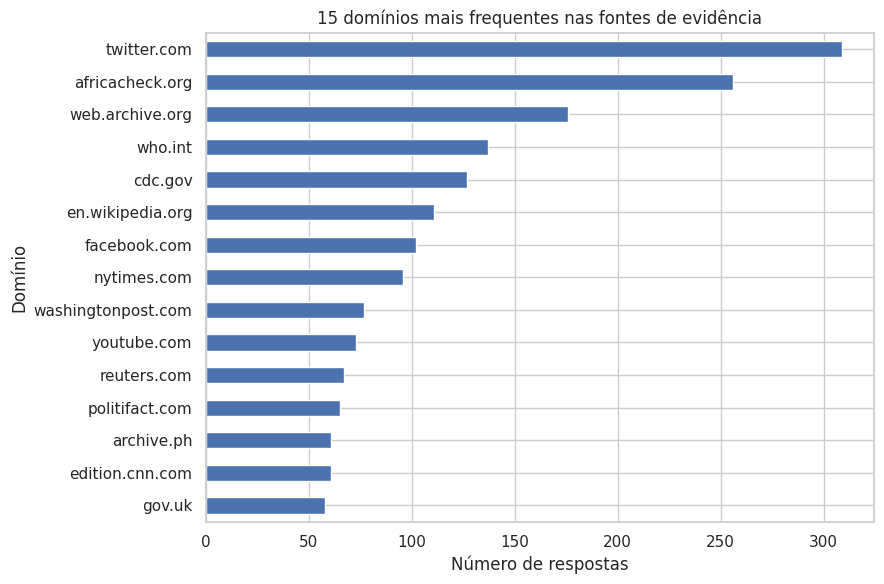

In [ ]:
# Visualização dos domínios mais frequentes

top15_dominios = (
    respostas_df["source_domain_original"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(9, 6))

top15_dominios.plot(kind="barh")

plt.title("15 domínios mais frequentes nas fontes de evidência")
plt.xlabel("Número de respostas")
plt.ylabel("Domínio")

plt.tight_layout()
plt.show()

### 9.10 Estrutura das evidências por classe

Após caracterizar a quantidade, os tipos e as fontes das evidências, será investigado se a estrutura de evidências apresenta diferenças entre as quatro classes de veracidade.

Nesta etapa, serão comparadas as quantidades de perguntas e respostas associadas às alegações de cada classe. O objetivo é verificar se determinadas categorias apresentam, em média, estruturas de evidência mais extensas do que outras.

Essa análise é descritiva e não pressupõe que eventuais diferenças sejam causadas pelo rótulo da alegação.

In [ ]:
# Quantidade de perguntas e respostas por classe

registros_evidencias = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:

        perguntas = registro.get("questions", [])

        n_perguntas = len(perguntas)
        n_respostas = sum(
            len(pergunta.get("answers", []))
            for pergunta in perguntas
        )

        registros_evidencias.append({
            "split": split_nome,
            "label": registro.get("label"),
            "n_questions": n_perguntas,
            "n_answers": n_respostas
        })

evidencias_claim_df = pd.DataFrame(registros_evidencias)

resumo_evidencias_classe = (
    evidencias_claim_df
    .groupby("label")
    .agg(
        alegacoes=("label", "size"),
        media_perguntas=("n_questions", "mean"),
        mediana_perguntas=("n_questions", "median"),
        media_respostas=("n_answers", "mean"),
        mediana_respostas=("n_answers", "median")
    )
    .round(2)
)

display(resumo_evidencias_classe)

,alegacoes,media_perguntas,mediana_perguntas,media_respostas,mediana_respostas
label,,,,,
Conflicting Evidence/Cherrypicking,233,3.60,3.0,3.97,4.0
Not Enough Evidence,317,2.80,2.0,2.95,2.0
Refuted,2047,2.51,2.0,2.67,2.0
Supported,971,2.49,2.0,2.64,2.0


#### Resultado da análise da estrutura das evidências por classe

A comparação entre as classes mostra diferenças na quantidade de perguntas e respostas associadas às alegações.

A classe `Conflicting Evidence/Cherrypicking` apresenta a estrutura de evidências mais extensa, com média de **3,60 perguntas** e **3,97 respostas por alegação**, além de medianas de **3 perguntas** e **4 respostas**.

A classe `Not Enough Evidence` apresenta valores intermediários, com média de **2,80 perguntas** e **2,95 respostas**, enquanto as classes `Refuted` e `Supported` apresentam valores bastante semelhantes entre si. Para `Refuted`, foram observadas médias de **2,51 perguntas** e **2,67 respostas**, enquanto `Supported` apresentou médias de **2,49 perguntas** e **2,64 respostas**. Nas três últimas classes, as medianas permaneceram em duas perguntas e duas respostas, com exceção da maior mediana observada em `Conflicting Evidence/Cherrypicking`.

Os resultados indicam, portanto, uma associação descritiva entre a classe da alegação e a extensão de sua estrutura de evidências, especialmente para `Conflicting Evidence/Cherrypicking`. Entretanto, essa diferença não permite concluir que o rótulo seja responsável pela maior quantidade de evidências, nem que a quantidade de perguntas ou respostas seja suficiente para determinar a classe de uma alegação.

In [ ]:
# Distribuição dos tipos de resposta dentro de cada classe

tipo_por_classe = pd.crosstab(
    respostas_df["label"],
    respostas_df["answer_type"],
    normalize="index"
).mul(100).round(2)

display(tipo_por_classe)

answer_type,Abstractive,Boolean,Extractive,Unanswerable
label,,,,
Conflicting Evidence/Cherrypicking,24.76,19.24,53.84,2.16
Not Enough Evidence,20.83,9.08,45.19,24.89
Refuted,25.58,18.20,53.56,2.66
Supported,29.92,13.01,56.02,1.05


#### Tipos de resposta por classe

A distribuição dos tipos de resposta também apresenta diferenças entre as classes.

As respostas `Extractive` são predominantes em todas as categorias, representando **53,84%** das respostas em `Conflicting Evidence/Cherrypicking`, **45,19%** em `Not Enough Evidence`, **53,56%** em `Refuted` e **56,02%** em `Supported`.

A principal diferença aparece na categoria `Unanswerable`. Enquanto esse tipo representa apenas **2,16%** das respostas em `Conflicting Evidence/Cherrypicking`, **2,66%** em `Refuted` e **1,05%** em `Supported`, sua participação alcança **24,89%** em `Not Enough Evidence`.

Também são observadas diferenças menores nos demais tipos. As respostas `Abstractive` variam de **20,83%** em `Not Enough Evidence` a **29,92%** em `Supported`, enquanto as respostas `Boolean` apresentam maior participação em `Conflicting Evidence/Cherrypicking` (**19,24%**) e `Refuted` (**18,20%**).

O resultado mostra que `Not Enough Evidence` apresenta uma composição de respostas distinta das demais classes, principalmente pela maior presença de perguntas classificadas como `Unanswerable`. Essa associação é relevante para a caracterização do conjunto, mas não implica que a presença de uma resposta `Unanswerable`, isoladamente, determine o rótulo da alegação.

answer_type,Abstractive,Boolean,Extractive,Unanswerable
label,,,,
Conflicting Evidence/Cherrypicking,229,178,498,20
Not Enough Evidence,195,85,423,233
Refuted,1396,993,2923,145
Supported,766,333,1434,27


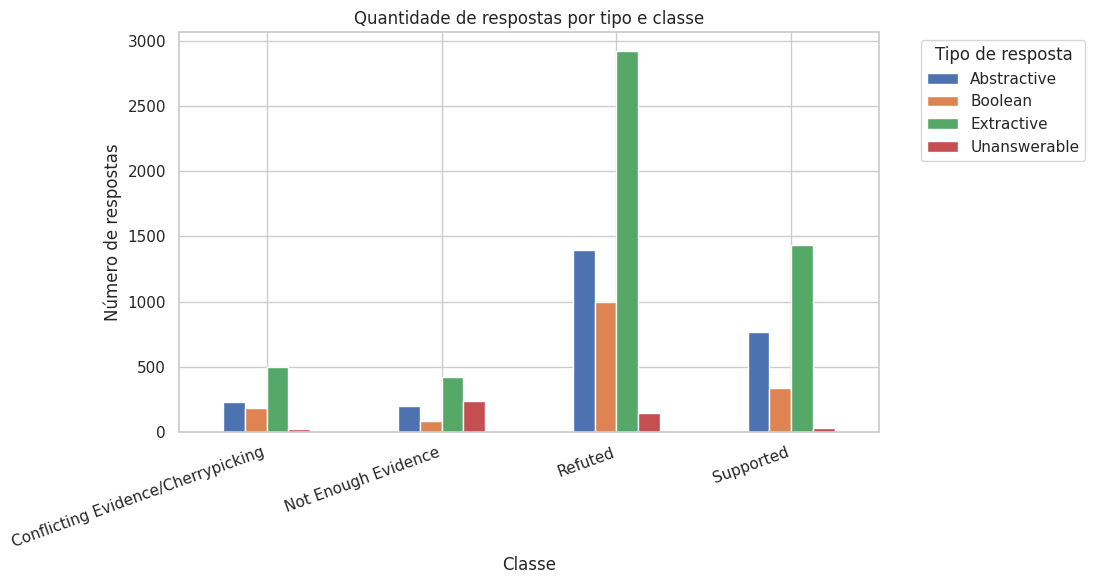

In [ ]:
# Quantidade absoluta dos tipos de resposta por classe

tipo_por_classe_contagem = pd.crosstab(
    respostas_df["label"],
    respostas_df["answer_type"]
)

display(tipo_por_classe_contagem)

tipo_por_classe_contagem.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Quantidade de respostas por tipo e classe")
plt.xlabel("Classe")
plt.ylabel("Número de respostas")
plt.xticks(rotation=20, ha="right")
plt.legend(
    title="Tipo de resposta",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

#### Distribuição absoluta dos tipos de resposta

A visualização das contagens absolutas complementa a análise percentual ao mostrar o volume de respostas associado a cada classe.

A classe `Refuted` concentra o maior número absoluto de respostas, comportamento compatível com sua maior frequência no conjunto de dados. As respostas `Extractive` também apresentam o maior volume absoluto em todas as classes.

Apesar do menor número de registros de `Not Enough Evidence`, observa-se uma presença expressiva de respostas `Unanswerable`. Esse resultado complementa a análise proporcional anterior, na qual esse tipo correspondeu a **24,89% das respostas da classe**, proporção substancialmente superior à observada nas demais categorias.

A análise conjunta das proporções e das contagens é importante porque as classes possuem tamanhos diferentes. Enquanto os percentuais permitem comparar a composição interna de cada classe, as contagens absolutas evidenciam o volume efetivo de respostas disponível em cada categoria.

## 10. Análise dos metadados das alegações

Além do conteúdo textual e da estrutura de evidências, o AVERITEC-BR apresenta metadados que ajudam a caracterizar as alegações e o processo de verificação.

Entre esses campos estão `claim_types`, `fact_checking_strategies`, `location_ISO_code`, `speaker` e `reporting_source`.

A análise desses metadados permite compreender melhor a composição do conjunto de dados, identificar categorias predominantes e verificar possíveis concentrações ou padrões que possam ser relevantes para a interpretação do dataset.

### 10.1 Tipos de alegação (`claim_types`)

O campo `claim_types` descreve os tipos associados a cada alegação. Como uma mesma alegação pode estar relacionada a mais de uma categoria, o campo possui estrutura multirrótulo.

Nesta etapa, as categorias serão separadas individualmente para analisar sua frequência no conjunto de dados. Dessa forma, a soma das ocorrências pode ser superior ao número total de alegações.

In [ ]:
# Distribuição dos tipos de alegação

claim_types_lista = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        tipos = registro.get("claim_types", [])

        if isinstance(tipos, list):
            for tipo in tipos:
                if not esta_ausente(tipo):
                    claim_types_lista.append({
                        "split": split_nome,
                        "claim_type": str(tipo).strip()
                    })

claim_types_df = pd.DataFrame(claim_types_lista)

print("Total de ocorrências de claim_types:", len(claim_types_df))
print("Tipos distintos:", claim_types_df["claim_type"].nunique())

print("\nDistribuição dos tipos de alegação:\n")

distribuicao_claim_types = (
    claim_types_df["claim_type"]
    .value_counts()
    .to_frame("quantidade")
)

distribuicao_claim_types["percentual_ocorrencias"] = (
    distribuicao_claim_types["quantidade"]
    / len(claim_types_df)
    * 100
).round(2)

display(distribuicao_claim_types)

Total de ocorrências de claim_types: 4271
Tipos distintos: 5

Distribuição dos tipos de alegação:



,quantidade,percentual_ocorrencias
claim_type,,
Event/Property Claim,2079,48.68
Numerical Claim,1154,27.02
Causal Claim,407,9.53
Quote Verification,364,8.52
Position Statement,267,6.25


#### Resultado da análise dos tipos de alegação

Foram identificadas **4.271 ocorrências de `claim_types`**, distribuídas entre **cinco categorias distintas**. Como uma mesma alegação pode receber mais de um tipo, o número de ocorrências é superior às 3.568 alegações analisadas.

A categoria mais frequente é `Event/Property Claim`, com **2.079 ocorrências (48,68%)**, representando quase metade das classificações de tipo presentes no conjunto. Em seguida aparece `Numerical Claim`, com **1.154 ocorrências (27,02%)**.

As demais categorias apresentam menor participação: `Causal Claim` corresponde a **9,53%** das ocorrências, `Quote Verification` a **8,52%** e `Position Statement` a **6,25%**.

A distribuição mostra, portanto, uma concentração principalmente em alegações relacionadas a eventos ou propriedades e em alegações numéricas, enquanto afirmações causais, verificações de citações e declarações de posicionamento aparecem com menor frequência.

Por se tratar de um campo multirrótulo, esses percentuais representam a participação de cada categoria no total de ocorrências de `claim_types` e não a proporção de alegações pertencentes exclusivamente a cada categoria.

#### Quantidade de tipos associados a cada alegação

Como `claim_types` é um campo multirrótulo, será analisada a quantidade de tipos atribuídos a cada alegação. Essa análise permite verificar se a classificação por tipo é predominantemente única ou se a associação de múltiplas categorias é frequente no conjunto de dados.

In [ ]:
# Quantidade de claim_types por alegação

n_tipos_por_claim = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        tipos = registro.get("claim_types", [])

        n_tipos_por_claim.append({
            "split": split_nome,
            "n_claim_types": len(tipos) if isinstance(tipos, list) else 0
        })

n_tipos_df = pd.DataFrame(n_tipos_por_claim)

distribuicao_n_tipos = (
    n_tipos_df["n_claim_types"]
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

distribuicao_n_tipos["percentual"] = (
    distribuicao_n_tipos["quantidade"]
    / len(n_tipos_df)
    * 100
).round(2)

display(distribuicao_n_tipos)

,quantidade,percentual
n_claim_types,,
1,2883,80.80
2,668,18.72
3,16,0.45
4,1,0.03


#### Resultado da quantidade de tipos por alegação

Embora `claim_types` permita a associação de múltiplas categorias a uma mesma alegação, a maior parte dos registros apresenta apenas um tipo.

Das **3.568 alegações analisadas**, **2.883 (80,80%)** possuem somente um `claim_type`, enquanto **668 (18,72%)** estão associadas a dois tipos. A presença de três ou mais categorias é pouco frequente: **16 alegações (0,45%)** possuem três tipos e apenas **uma alegação (0,03%)** apresenta quatro tipos.

Dessa forma, embora a classificação seja multirrótulo, a atribuição de uma única categoria predomina no conjunto. Ainda assim, aproximadamente **19,20% das alegações possuem mais de um tipo**, indicando que uma parcela relevante dos registros não pode ser caracterizada por uma única categoria de alegação.

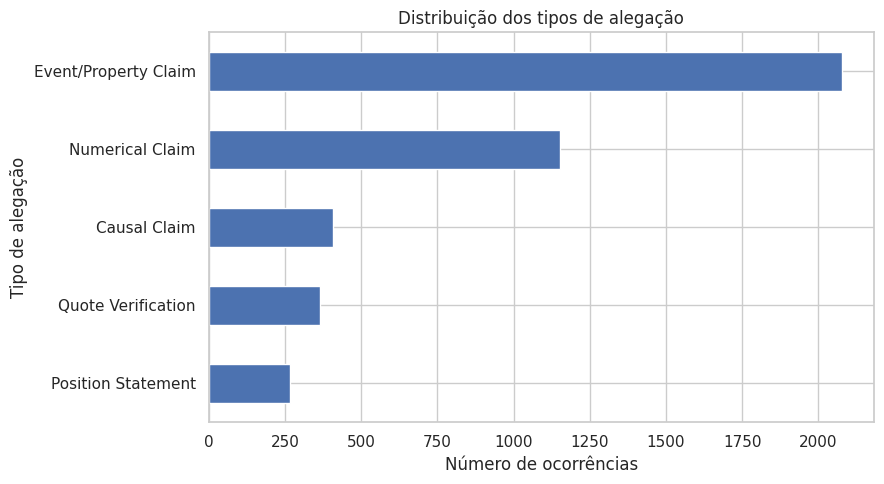

In [ ]:
# Distribuição dos tipos de alegação

claim_types_plot = (
    claim_types_df["claim_type"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))

claim_types_plot.plot(kind="barh")

plt.title("Distribuição dos tipos de alegação")
plt.xlabel("Número de ocorrências")
plt.ylabel("Tipo de alegação")

plt.tight_layout()
plt.show()

### 10.2 Estratégias de checagem (`fact_checking_strategies`)

O campo `fact_checking_strategies` descreve as estratégias de verificação associadas a cada alegação.

Assim como `claim_types`, esse campo pode conter mais de uma categoria para o mesmo registro. Por esse motivo, as estratégias serão analisadas individualmente, permitindo identificar quais métodos de checagem aparecem com maior frequência no conjunto de dados.

Como uma mesma alegação pode estar associada a múltiplas estratégias, o número total de ocorrências pode ser superior ao número de alegações analisadas.

In [ ]:
# Distribuição das estratégias de checagem

estrategias_lista = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        estrategias = registro.get("fact_checking_strategies", [])

        if isinstance(estrategias, list):
            for estrategia in estrategias:
                if not esta_ausente(estrategia):
                    estrategias_lista.append({
                        "split": split_nome,
                        "fact_checking_strategy": str(estrategia).strip()
                    })

estrategias_df = pd.DataFrame(estrategias_lista)

print(
    "Total de ocorrências de fact_checking_strategies:",
    len(estrategias_df)
)

print(
    "Estratégias distintas:",
    estrategias_df["fact_checking_strategy"].nunique()
)

print("\nDistribuição das estratégias de checagem:\n")

distribuicao_estrategias = (
    estrategias_df["fact_checking_strategy"]
    .value_counts()
    .to_frame("quantidade")
)

distribuicao_estrategias["percentual_ocorrencias"] = (
    distribuicao_estrategias["quantidade"]
    / len(estrategias_df)
    * 100
).round(2)

display(distribuicao_estrategias)

Total de ocorrências de fact_checking_strategies: 5303
Estratégias distintas: 5

Distribuição das estratégias de checagem:



,quantidade,percentual_ocorrencias
fact_checking_strategy,,
Written Evidence,2862,53.97
Consultation,1047,19.74
Numerical Comparison,1035,19.52
Fact-checker Reference,238,4.49
Satirical Source Identification,121,2.28


#### Resultado da análise das estratégias de checagem

Foram identificadas **5.303 ocorrências de `fact_checking_strategies`**, distribuídas entre **cinco estratégias distintas**. Como uma mesma alegação pode estar associada a mais de uma estratégia, o número de ocorrências é superior ao total de 3.568 alegações analisadas.

A estratégia predominante é `Written Evidence`, com **2.862 ocorrências (53,97%)**, representando mais da metade das estratégias registradas no conjunto.

Em seguida aparecem `Consultation`, com **1.047 ocorrências (19,74%)**, e `Numerical Comparison`, com **1.035 (19,52%)**, apresentando frequências bastante semelhantes.

As estratégias `Fact-checker Reference` e `Satirical Source Identification` são menos frequentes, correspondendo, respectivamente, a **4,49%** e **2,28%** das ocorrências.

Os resultados mostram que a utilização de evidências escritas ocupa posição central no processo de verificação representado pelo conjunto de dados, embora outras estratégias, especialmente consulta e comparação numérica, também apresentem participação relevante.

Assim como em `claim_types`, os percentuais representam a participação de cada estratégia no total de ocorrências e não a proporção de alegações que utilizam exclusivamente cada estratégia.

#### Quantidade de estratégias associadas a cada alegação

Como uma mesma alegação pode utilizar múltiplas estratégias de checagem, será analisada a quantidade de estratégias associadas a cada registro.

Essa análise permite verificar se a utilização de uma única estratégia é predominante ou se a combinação de diferentes formas de verificação é frequente no conjunto de dados.

In [ ]:
# Quantidade de estratégias de checagem por alegação

n_estrategias_por_claim = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        estrategias = registro.get("fact_checking_strategies", [])

        n_estrategias_por_claim.append({
            "split": split_nome,
            "n_strategies": (
                len(estrategias)
                if isinstance(estrategias, list)
                else 0
            )
        })

n_estrategias_df = pd.DataFrame(n_estrategias_por_claim)

distribuicao_n_estrategias = (
    n_estrategias_df["n_strategies"]
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

distribuicao_n_estrategias["percentual"] = (
    distribuicao_n_estrategias["quantidade"]
    / len(n_estrategias_df)
    * 100
).round(2)

display(distribuicao_n_estrategias)

,quantidade,percentual
n_strategies,,
1,2037,57.09
2,1334,37.39
3,190,5.33
4,7,0.20


#### Resultado da quantidade de estratégias por alegação

A análise mostra que **2.037 alegações (57,09%)** estão associadas a apenas uma estratégia de checagem. Entretanto, a utilização de múltiplas estratégias também é frequente no conjunto de dados.

Foram identificadas **1.334 alegações (37,39%)** associadas a duas estratégias, enquanto **190 (5,33%)** utilizam três estratégias e **7 (0,20%)** apresentam quatro estratégias.

Dessa forma, **42,91% das alegações estão associadas a mais de uma estratégia de checagem**, mostrando que a verificação representada no conjunto de dados não se limita, em uma parcela relevante dos casos, à utilização de uma única abordagem.

Esse resultado também diferencia `fact_checking_strategies` de `claim_types`: embora ambos sejam campos multirrótulo, a combinação de múltiplas estratégias de checagem aparece com maior frequência do que a associação de múltiplos tipos de alegação.

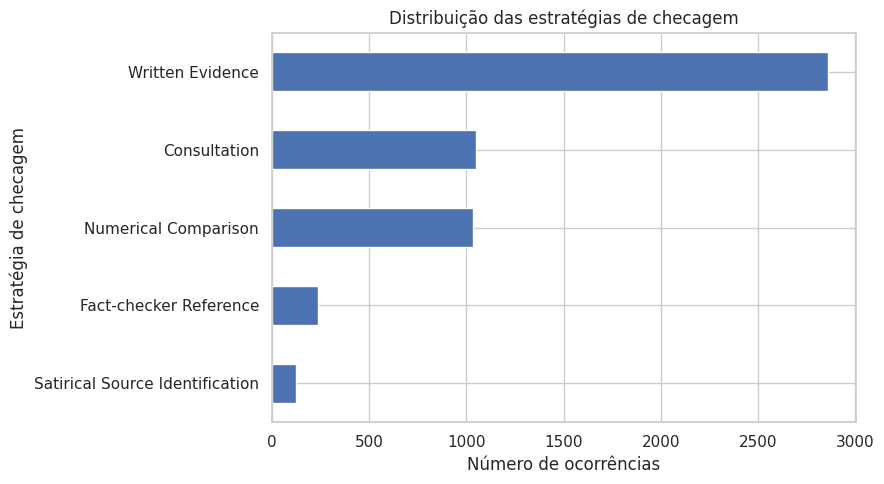

In [ ]:
# Distribuição das estratégias de checagem

estrategias_plot = (
    estrategias_df["fact_checking_strategy"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(9, 5))

estrategias_plot.plot(kind="barh")

plt.title("Distribuição das estratégias de checagem")
plt.xlabel("Número de ocorrências")
plt.ylabel("Estratégia de checagem")

plt.tight_layout()
plt.show()

### 10.3 Distribuição geográfica das alegações (`location_ISO_code`)

O campo `location_ISO_code` fornece informações sobre a localização geográfica associada às alegações por meio de códigos de país.

A análise desse campo permite investigar a diversidade geográfica presente no AVERITEC-BR e verificar se determinadas localidades estão mais representadas no conjunto de dados.

Como foram identificados anteriormente registros sem informação nesse campo, as ausências serão mantidas separadas da análise das localidades efetivamente informadas.

In [ ]:
# Distribuição dos códigos de localização

localizacoes = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        localizacao = registro.get("location_ISO_code")

        if not esta_ausente(localizacao):
            localizacoes.append({
                "split": split_nome,
                "location_ISO_code": str(localizacao).strip()
            })

localizacoes_df = pd.DataFrame(localizacoes)

print("Registros com localização informada:", len(localizacoes_df))
print(
    "Códigos de localização distintos:",
    localizacoes_df["location_ISO_code"].nunique()
)

print("\n20 códigos mais frequentes:\n")

top_localizacoes = (
    localizacoes_df["location_ISO_code"]
    .value_counts()
    .head(20)
)

display(top_localizacoes.to_frame("quantidade"))

Registros com localização informada: 3182
Códigos de localização distintos: 70

20 códigos mais frequentes:



,quantidade
location_ISO_code,
US,1461
IN,404
GB,259
NG,247
KE,233
ZA,162
PH,53
CN,47
AU,42


#### Resultado da análise da distribuição geográfica

Dos **3.568 registros analisados**, **3.182 possuem informação em `location_ISO_code`**, enquanto os demais apresentam ausência nesse campo.

Entre os registros com localização informada, foram identificados **70 códigos distintos**, indicando diversidade geográfica no conjunto de dados. Entretanto, essa distribuição apresenta concentração expressiva em algumas localidades.

Os Estados Unidos (`US`) aparecem com maior frequência, com **1.461 registros**, seguidos por Índia (`IN`), com **404**, Reino Unido (`GB`), com **259**, Nigéria (`NG`), com **247**, Quênia (`KE`), com **233**, e África do Sul (`ZA`), com **162 registros**.

Após essas localidades, as frequências diminuem consideravelmente. Filipinas (`PH`) apresentam 53 registros, China (`CN`) 47, Austrália (`AU`) 42 e Rússia (`RU`) 34, enquanto as demais localidades entre as mais frequentes apresentam números ainda menores.

Dessa forma, embora o conjunto inclua alegações associadas a diversas localidades, a representação geográfica não é uniforme. A concentração em determinados países, especialmente nos Estados Unidos, deve ser considerada na caracterização do dataset, pois os padrões observados no conjunto podem refletir com maior intensidade os contextos mais representados.

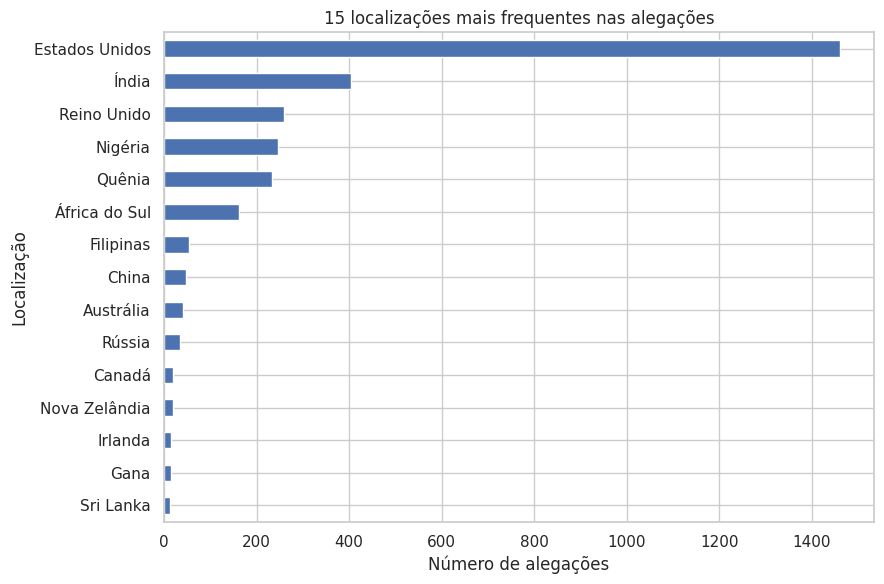

In [ ]:
# Conversão dos códigos mais frequentes para nomes dos países

nomes_paises = {
    "US": "Estados Unidos",
    "IN": "Índia",
    "GB": "Reino Unido",
    "NG": "Nigéria",
    "KE": "Quênia",
    "ZA": "África do Sul",
    "PH": "Filipinas",
    "CN": "China",
    "AU": "Austrália",
    "RU": "Rússia",
    "CA": "Canadá",
    "NZ": "Nova Zelândia",
    "GH": "Gana",
    "IE": "Irlanda",
    "LK": "Sri Lanka"
}

top15_localizacoes = (
    localizacoes_df["location_ISO_code"]
    .value_counts()
    .head(15)
)

top15_localizacoes.index = [
    nomes_paises.get(codigo, codigo)
    for codigo in top15_localizacoes.index
]

top15_localizacoes = top15_localizacoes.sort_values()

plt.figure(figsize=(9, 6))

top15_localizacoes.plot(kind="barh")

plt.title("15 localizações mais frequentes nas alegações")
plt.xlabel("Número de alegações")
plt.ylabel("Localização")

plt.tight_layout()
plt.show()

### 10.4 Autores/oradores das alegações (`speaker`)

O campo `speaker` identifica, quando disponível, a pessoa ou entidade associada à alegação.

A análise desse metadado permite verificar a diversidade de autores presentes no conjunto de dados e identificar se determinadas pessoas ou entidades aparecem com maior frequência.

Como a análise de qualidade mostrou uma proporção relevante de valores ausentes nesse campo, esta etapa considera apenas os registros em que `speaker` está preenchido. As ausências permanecem registradas como uma limitação dos metadados disponíveis.

In [ ]:
# Distribuição dos autores/oradores das alegações

speakers = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        speaker = registro.get("speaker")

        if not esta_ausente(speaker):
            speakers.append({
                "split": split_nome,
                "speaker": str(speaker).strip()
            })

speakers_df = pd.DataFrame(speakers)

print("Registros com speaker informado:", len(speakers_df))
print("Speakers distintos:", speakers_df["speaker"].nunique())

print("\n20 speakers mais frequentes:\n")

top_speakers = (
    speakers_df["speaker"]
    .value_counts()
    .head(20)
)

display(top_speakers.to_frame("quantidade"))

Registros com speaker informado: 2755
Speakers distintos: 1536

20 speakers mais frequentes:



,quantidade
speaker,
Donald Trump,223
Cyril Ramaphosa,74
Joe Biden,59
Uhuru Kenyatta,49
Wycliffe Oparanya,46
Bernie Sanders,33
US President Donald Trump,32
Socrates Mbamalu,28
William Ruto,28


#### Resultado inicial da análise de autores/oradores

Entre as 3.568 alegações analisadas, **2.755 possuem informação no campo `speaker`**, com **1.536 valores distintos** registrados.

A distribuição inicial mostra que alguns autores aparecem com maior frequência, com destaque para `Donald Trump`, presente em 223 registros, seguido por `Cyril Ramaphosa` (74), `Joe Biden` (59), `Uhuru Kenyatta` (49) e `Wycliffe Oparanya` (46).

Entretanto, a inspeção dos valores mais frequentes revelou variações na forma de registro de um mesmo autor. Por exemplo, aparecem separadamente `Donald Trump`, `US President Donald Trump` e `Donald trump`. De forma semelhante, foram encontrados `Muhammadu Buhari` e `President Muhammadu Buhari`.

Essas variações indicam que a contagem direta dos valores de `speaker` pode fragmentar a frequência de um mesmo autor. Além disso, o campo não contém exclusivamente nomes individuais, como demonstra a presença de categorias mais genéricas, como `Social Media Users`.

Por esse motivo, a distribuição bruta deve ser interpretada com cautela antes da produção de uma visualização dos autores mais frequentes.

#### Verificação de variações de escrita em `speaker`

Para avaliar inconsistências simples de padronização, os valores de `speaker` serão comparados após uma normalização conservadora, considerando apenas diferenças entre letras maiúsculas e minúsculas e espaços excedentes.

Títulos, cargos ou outras partes dos nomes não serão removidos automaticamente, evitando agrupar registros que possam ter sido anotados de maneira intencionalmente distinta.

In [ ]:
# Normalização conservadora dos valores de speaker

speakers_df["speaker_normalizado"] = (
    speakers_df["speaker"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Speakers distintos antes da normalização:",
      speakers_df["speaker"].nunique())

print("Speakers distintos após normalização:",
      speakers_df["speaker_normalizado"].nunique())

# Identificar formas normalizadas que possuem mais de uma grafia original
variantes_speaker = (
    speakers_df
    .groupby("speaker_normalizado")["speaker"]
    .nunique()
)

variantes_speaker = variantes_speaker[
    variantes_speaker > 1
].sort_values(ascending=False)

print("\nSpeakers com mais de uma variação de escrita:",
      len(variantes_speaker))

display(variantes_speaker.head(20).to_frame("n_variacoes"))

Speakers distintos antes da normalização: 1536
Speakers distintos após normalização: 1519

Speakers com mais de uma variação de escrita: 15


,n_variacoes
speaker_normalizado,
donald trump,3
social media users,3
buhari,2
chuck schumer,2
eric swalwell,2
fammtv,2
bjp government,2
julian castro,2
kenyan president uhuru kenyatta,2


#### Resultado da verificação de variações de escrita

A normalização conservadora do campo `speaker`, considerando apenas diferenças entre letras maiúsculas e minúsculas e espaços excedentes, reduziu o número de valores distintos de **1.536 para 1.519**.

Foram identificadas **15 formas normalizadas associadas a mais de uma grafia original**. Entre os exemplos estão `Donald Trump`, `Social Media Users`, `Chuck Schumer`, `Mike Pence` e `US President Donald Trump`.

A diferença relativamente pequena entre o número de valores distintos antes e depois da normalização indica que inconsistências simples de capitalização ou espaçamento estão presentes, mas não constituem um problema predominante no campo.

Entretanto, a inspeção anterior também revelou variações que não são resolvidas por essa normalização, como a presença ou ausência de títulos e cargos. Casos como `Donald Trump` e `US President Donald Trump`, por exemplo, permanecem como valores distintos.

Essas formas não serão agrupadas automaticamente nesta etapa, pois uma padronização semântica exigiria critérios adicionais e poderia combinar registros cuja distinção tenha sido preservada durante a anotação. Assim, as frequências brutas de `speaker` devem ser interpretadas considerando essa heterogeneidade de representação.

### 10.5 Fontes de publicação das alegações (`reporting_source`)

O campo `reporting_source` fornece informações sobre a fonte ou meio associado à publicação da alegação.

Essa informação é diferente das fontes utilizadas como evidência no processo de verificação, analisadas anteriormente por meio de `source_url`. Enquanto as URLs das evidências representam materiais utilizados para verificar uma alegação, `reporting_source` caracteriza a origem ou o meio associado à própria alegação.

Como esse campo apresenta valores ausentes, a análise considera inicialmente apenas os registros em que a informação está disponível.

In [ ]:
# Análise de reporting_source

reporting_sources = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for registro in dados:
        fonte = registro.get("reporting_source")

        if not esta_ausente(fonte):
            reporting_sources.append({
                "split": split_nome,
                "reporting_source": str(fonte).strip()
            })

reporting_sources_df = pd.DataFrame(reporting_sources)

print("Registros com reporting_source informado:",
      len(reporting_sources_df))

print("Reporting sources distintos:",
      reporting_sources_df["reporting_source"].nunique())

print("\n20 reporting sources mais frequentes:\n")

top_reporting_sources = (
    reporting_sources_df["reporting_source"]
    .value_counts()
    .head(20)
)

display(top_reporting_sources.to_frame("quantidade"))

Registros com reporting_source informado: 2863
Reporting sources distintos: 678

20 reporting sources mais frequentes:



,quantidade
reporting_source,
Facebook,954
Twitter,371
Youtube,40
YouTube,37
Social Media,31
twitter,31
Instagram,30
CNN,30
facebook,28


#### Resultado inicial da análise das fontes de publicação

Dos 3.568 registros analisados, **2.863 possuem informação no campo `reporting_source`**, correspondendo a aproximadamente 80% do conjunto. Entre os valores preenchidos, foram identificadas **678 formas distintas** de fonte de publicação.

A distribuição inicial apresenta forte presença de plataformas digitais. `Facebook` aparece como a fonte mais frequente, com 954 registros, seguido por `Twitter`, com 371. Também aparecem `YouTube`, `Instagram` e `WhatsApp`, além de veículos jornalísticos e outros contextos de publicação.

A inspeção dos valores revelou, entretanto, diferenças simples de padronização. Por exemplo, `Facebook` e `facebook`, `Twitter` e `twitter`, assim como `Youtube` e `YouTube`, aparecem como categorias distintas na representação original.

Além disso, o campo não representa exclusivamente plataformas ou veículos de comunicação. Alguns valores descrevem contextos específicos de publicação ou declaração, como entrevistas, coletivas de imprensa, convenções e discursos. Dessa forma, `reporting_source` deve ser interpretado como um metadado heterogêneo sobre a origem ou contexto de circulação da alegação, e não como uma classificação padronizada de plataformas.

#### Padronização conservadora de `reporting_source`

Para reduzir diferenças puramente ortográficas na representação das fontes, será aplicada uma normalização conservadora considerando apenas letras maiúsculas e minúsculas e espaços excedentes.

Não serão agrupadas automaticamente fontes semanticamente semelhantes ou descrições relacionadas ao mesmo veículo, preservando a representação original do conjunto de dados.

In [ ]:
# Normalização conservadora de reporting_source

reporting_sources_df["reporting_source_normalizado"] = (
    reporting_sources_df["reporting_source"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print(
    "Reporting sources distintos antes da normalização:",
    reporting_sources_df["reporting_source"].nunique()
)

print(
    "Reporting sources distintos após normalização:",
    reporting_sources_df["reporting_source_normalizado"].nunique()
)

# Formas normalizadas associadas a mais de uma grafia original
variantes_reporting = (
    reporting_sources_df
    .groupby("reporting_source_normalizado")["reporting_source"]
    .nunique()
)

variantes_reporting = variantes_reporting[
    variantes_reporting > 1
].sort_values(ascending=False)

print(
    "\nFontes com mais de uma variação de escrita:",
    len(variantes_reporting)
)

display(
    variantes_reporting.head(20).to_frame("n_variacoes")
)

print("\n20 fontes mais frequentes após normalização:\n")

top_reporting_normalizado = (
    reporting_sources_df["reporting_source_normalizado"]
    .value_counts()
    .head(20)
)

display(
    top_reporting_normalizado.to_frame("quantidade")
)

Reporting sources distintos antes da normalização: 678
Reporting sources distintos após normalização: 609

Fontes com mais de uma variação de escrita: 54


,n_variacoes
reporting_source_normalizado,
c-span,4
fox news,4
democracy day address,3
cbs news,3
bustatroll.org,3
"facebook, twitter",3
facebook,3
nbc news,3
twitter,3



20 fontes mais frequentes após normalização:



,quantidade
reporting_source_normalizado,
facebook,987
twitter,403
youtube,86
instagram,32
social media,32
fox news,30
cnn,30
al jazeera,25
whatsapp,25


#### Resultado da normalização das fontes de publicação

A normalização conservadora reduziu o número de valores distintos de `reporting_source` de **678 para 609**, mostrando que parte da diversidade inicialmente observada era decorrente de diferenças simples de capitalização ou espaçamento.

Foram identificadas **54 formas normalizadas associadas a mais de uma grafia original**. Entre os casos observados estão fontes como `facebook`, `twitter`, `youtube`, `instagram`, `fox news`, `cbs news` e `c-span`.

Após a normalização, `facebook` permanece como a fonte de publicação mais frequente, com **987 registros**, seguido por `twitter`, com **403**, e `youtube`, com **86**. Também aparecem `instagram`, `social media`, `whatsapp`, veículos jornalísticos como `CNN`, `Fox News` e `Al Jazeera`, além de diferentes contextos de declaração pública.

Os resultados evidenciam uma presença expressiva de plataformas digitais entre as origens registradas das alegações. Entretanto, o campo apresenta natureza heterogênea: além de redes sociais e veículos de comunicação, também contém descrições de discursos, reuniões, coletivas de imprensa, eventos políticos e outros contextos de publicação.

Dessa forma, `reporting_source` fornece informações relevantes sobre a origem ou circulação das alegações, mas não constitui uma taxonomia padronizada de meios de comunicação. Essa heterogeneidade deve ser considerada caso o campo seja utilizado em etapas posteriores.

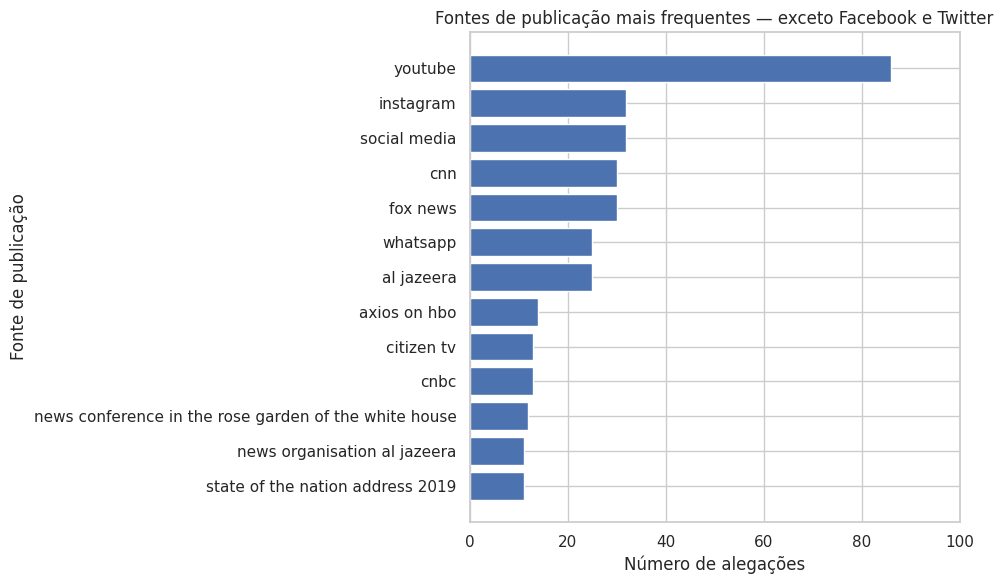

In [ ]:
# Fontes mais frequentes, excluindo Facebook e Twitter para melhorar a visualização

fontes_sem_dominantes = (
    reporting_sources_df.loc[
        ~reporting_sources_df["reporting_source_normalizado"].isin(
            ["facebook", "twitter"]
        ),
        "reporting_source_normalizado"
    ]
    .value_counts()
    .head(13)
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    fontes_sem_dominantes.index,
    fontes_sem_dominantes.values
)

plt.title("Fontes de publicação mais frequentes — exceto Facebook e Twitter")
plt.xlabel("Número de alegações")
plt.ylabel("Fonte de publicação")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

#### Visualização das demais fontes de publicação

Como `facebook` (987 registros) e `twitter` (403) apresentam frequências muito superiores às demais fontes, essas duas categorias foram excluídas apenas da visualização acima, permitindo observar com maior clareza a distribuição das fontes restantes.

Entre as demais categorias, `youtube` apresenta a maior frequência, com 86 registros. Em seguida aparecem `instagram` e `social media`, com 32 registros cada, além de veículos jornalísticos como `CNN`, `Fox News` e `Al Jazeera`.

A exclusão de `facebook` e `twitter` neste gráfico não altera a análise dos dados e foi realizada exclusivamente para melhorar a escala e a legibilidade da visualização.

## 11. Análise lexical das alegações

Após a análise estrutural, das evidências e dos metadados, esta etapa investiga os padrões lexicais presentes no texto das alegações do AVERITEC-BR.

O objetivo é identificar termos e combinações de palavras recorrentes, permitindo observar temas, nomes e expressões que aparecem com maior frequência no conjunto de dados.

Para essa análise, será criada uma versão preparada das alegações exclusivamente para exploração lexical. Os textos originais serão preservados no dataset.


### 11.1 Preparação dos textos para análise lexical

A preparação textual incluirá:

- conversão para letras minúsculas;
- remoção de URLs;
- remoção de números, pontuação e caracteres especiais;
- remoção de *stopwords* da língua portuguesa;
- preservação das palavras `não` e `nem`, por representarem negação e poderem carregar informação semanticamente relevante.

Não serão aplicadas técnicas de *stemming* ou lematização nesta etapa, preservando as formas das palavras presentes na tradução das alegações.

In [ ]:
# Preparação dos textos para análise lexical

import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stopwords_pt = set(stopwords.words("portuguese"))

# Preservar termos de negação
stopwords_pt.discard("não")
stopwords_pt.discard("nem")


def limpar_texto_lexical(texto):
    if esta_ausente(texto):
        return ""

    texto = str(texto).lower()

    # Remove URLs
    texto = re.sub(r"http\S+|www\S+", " ", texto)

    # Mantém apenas caracteres alfabéticos e espaços
    texto = re.sub(r"[^a-záàâãéèêíïóôõöúçñ\s]", " ", texto)

    # Remove espaços duplicados
    texto = re.sub(r"\s+", " ", texto).strip()

    palavras = [
        palavra
        for palavra in texto.split()
        if palavra not in stopwords_pt
    ]

    return " ".join(palavras)


# Reunir as claims de Train e Dev
claims_lexical = []

for split_nome, dados in [
    ("Train", train_raw),
    ("Dev", dev_raw)
]:
    for indice, registro in enumerate(dados):

        claim = registro.get("claim")

        # O registro sem claim não entra na análise textual
        if not esta_ausente(claim):

            claims_lexical.append({
                "split": split_nome,
                "claim_index": indice,
                "label": registro.get("label"),
                "claim_original": claim,
                "claim_limpa": limpar_texto_lexical(claim)
            })


claims_lexical_df = pd.DataFrame(claims_lexical)

print("Alegações utilizadas na análise lexical:",
      len(claims_lexical_df))

print("\nExemplos antes e depois da preparação:\n")

display(
    claims_lexical_df[
        ["claim_original", "claim_limpa"]
    ].head(10)
)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Alegações utilizadas na análise lexical: 3567

Exemplos antes e depois da preparação:



,claim_original,claim_limpa
0,Hunter Biden não tinha experiência na Ucrânia ou no setor de energia quando se juntou ao conselho da Burisma.,hunter biden não experiência ucrânia setor energia juntou conselho burisma
1,Donald Trump entregou os maiores cortes de impostos da história americana.,donald trump entregou maiores cortes impostos história americana
2,"Na Nigéria… em termos de participação na receita, 20% vai para o governo local.",nigéria termos participação receita vai governo local
3,Biden prometeu parar a construção de muros na fronteira e conceder amnistia e assistência médica a todos os imigrantes ilegais.,biden prometeu parar construção muros fronteira conceder amnistia assistência médica todos imigrantes ilegais
4,"Após o tiroteio da polícia em Jacob Blake, o governador Tony Evers e o vice-governador Mandela Barnes não pediram por paz ou incentivaram a calma.",após tiroteio polícia jacob blake governador tony evers vice governador mandela barnes não pediram paz incentivaram calma
5,"O Teste Comum de Admissão (CLAT) de 2020 não será realizado em 7 de setembro de 2020, conforme o planejado.",teste comum admissão clat não realizado setembro conforme planejado
6,35% da receita vai para os estados. (Na Nigéria),receita vai estados nigéria
7,Margaret Sanger era uma racista que acreditava em eugenia. Sua meta ao fundar o Planned Parenthood era erradicar minorias.,margaret sanger racista acreditava eugenia meta fundar planned parenthood erradicar minorias
8,"Joe Biden votou a favor da Guerra do Iraque e apoiou a guerra na Sérvia, Síria e Líbia.",joe biden votou favor guerra iraque apoiou guerra sérvia síria líbia
9,Biden vai tirar o Segundo Emendamento.,biden vai tirar segundo emendamento


#### Resultado da preparação textual

Foram utilizadas **3.567 alegações** na análise lexical. Apenas o registro anteriormente identificado sem conteúdo no campo `claim` foi excluído desta etapa.

A inspeção dos textos antes e depois da preparação mostra que o procedimento removeu elementos pouco informativos para a análise de frequência, como pontuação, números, URLs e *stopwords*, preservando os principais termos presentes nas alegações.

As palavras `não` e `nem` foram mantidas intencionalmente, uma vez que expressões de negação podem alterar o significado das afirmações e são particularmente relevantes em textos relacionados à verificação de informações.

Também foram preservados nomes próprios e expressões presentes nas alegações, permitindo que pessoas, organizações, localidades e outros termos recorrentes sejam identificados nas análises de frequência.

A versão preparada será utilizada exclusivamente para a exploração lexical, mantendo os textos originais inalterados.

### 11.2 Palavras mais frequentes

A frequência das palavras será analisada a partir das versões preparadas das alegações.

Essa etapa permite identificar termos recorrentes no conjunto e observar possíveis temas, pessoas, localidades ou expressões que caracterizam o conteúdo das alegações.

Inicialmente, serão examinadas as palavras mais frequentes antes de qualquer remoção adicional de termos específicos da visualização.

In [ ]:
# Frequência das palavras

todas_palavras = []

for texto in claims_lexical_df["claim_limpa"]:
    todas_palavras.extend(texto.split())

frequencia_palavras = Counter(todas_palavras)

top_palavras = pd.DataFrame(
    frequencia_palavras.most_common(30),
    columns=["palavra", "frequencia"]
)

display(top_palavras)

,palavra,frequencia
0,não,461
1,eua,404
2,covid,356
3,trump,330
4,presidente,315
5,pessoas,252
6,milhões,234
7,anos,233
8,coronavírus,200
9,disse,198


#### Resultado inicial da frequência de palavras

A análise das palavras mais frequentes mostra a presença de termos relacionados a diferentes temas, localidades e figuras públicas representadas no conjunto de dados.

A palavra `não` é a mais frequente, com **461 ocorrências**, resultado relevante considerando que termos de negação foram preservados intencionalmente durante a preparação textual.

Entre os termos de maior frequência também aparecem referências geográficas, como `eua`, `nigéria`, `índia`, `quênia`, `áfrica`, `estados` e `unidos`, além de nomes associados a figuras públicas, como `trump`, `donald` e `biden`.

Termos relacionados à pandemia e à saúde também possuem presença expressiva, incluindo `covid`, `coronavírus`, `pandemia` e `saúde`. Outros termos recorrentes, como `governo`, `presidente`, `lei`, `milhões` e `pessoas`, indicam a presença de alegações relacionadas a temas políticos, institucionais, sociais e quantitativos.

Foi identificado também o termo `sobre`, com 134 ocorrências. Embora frequente, essa palavra possui baixo valor temático isoladamente e será removida apenas da visualização das palavras mais frequentes, sem alterar os textos originais nem a versão preparada utilizada nas demais análises.

,palavra,frequencia
0,não,461
1,eua,404
2,covid,356
3,trump,330
4,presidente,315
5,pessoas,252
6,milhões,234
7,anos,233
8,coronavírus,200
9,disse,198


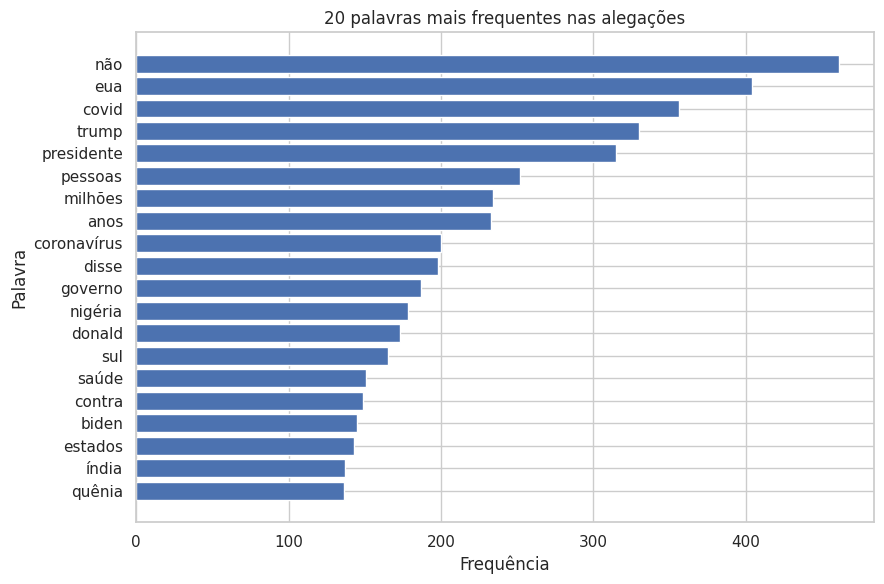

In [ ]:
# Remoção de termo pouco informativo apenas para a visualização

termos_excluir_visualizacao = {"sobre"}

frequencia_visualizacao = Counter(
    palavra
    for palavra in todas_palavras
    if palavra not in termos_excluir_visualizacao
)

top20_palavras = pd.DataFrame(
    frequencia_visualizacao.most_common(20),
    columns=["palavra", "frequencia"]
)

display(top20_palavras)

# Gráfico das palavras mais frequentes

top20_plot = top20_palavras.sort_values("frequencia")

plt.figure(figsize=(9, 6))

plt.barh(
    top20_plot["palavra"],
    top20_plot["frequencia"]
)

plt.title("20 palavras mais frequentes nas alegações")
plt.xlabel("Frequência")
plt.ylabel("Palavra")

plt.tight_layout()
plt.show()

### 11.3 Bigramas mais frequentes

A análise de palavras individuais permite identificar termos recorrentes, mas não mostra como esses termos aparecem combinados nas alegações.

Por esse motivo, serão analisados também os bigramas, isto é, sequências formadas por duas palavras consecutivas. Essa análise permite identificar nomes compostos, localidades, expressões e temas recorrentes que podem não ser evidentes a partir da frequência das palavras isoladas.

Os bigramas serão construídos a partir dos textos preparados anteriormente, mantendo o mesmo procedimento de limpeza utilizado na análise lexical.

In [ ]:
# Frequência dos bigramas

bigramas = []

for texto in claims_lexical_df["claim_limpa"]:
    palavras = texto.split()

    bigramas.extend(
        zip(palavras, palavras[1:])
    )

frequencia_bigramas = Counter(bigramas)

top30_bigramas = pd.DataFrame(
    [
        (" ".join(bigrama), frequencia)
        for bigrama, frequencia in frequencia_bigramas.most_common(30)
    ],
    columns=["bigrama", "frequencia"]
)

display(top30_bigramas)

,bigrama,frequencia
0,donald trump,170
1,estados unidos,117
2,áfrica sul,93
3,joe biden,82
4,reino unido,81
5,presidente eua,60
6,cinco anos,43
7,presidente donald,42
8,primeiro ministro,42
9,pandemia covid,39


#### Resultado da análise dos bigramas

A análise dos bigramas evidencia combinações recorrentes que complementam os resultados obtidos com as palavras individuais.

O bigrama mais frequente é `donald trump`, com **170 ocorrências**, seguido por `estados unidos` (**117**), `áfrica sul` (**93**), `joe biden` (**82**) e `reino unido` (**81**).

Diversas combinações estão relacionadas a figuras e estruturas políticas, como `presidente eua`, `presidente donald`, `primeiro ministro`, `vice presidente`, `presidente trump`, `barack obama`, `projeto lei` e `suprema corte`.

Também aparecem combinações relacionadas à pandemia e à saúde, como `pandemia covid`, `contra covid`, `organização mundial`, `mundial saúde`, `vacina contra`, `novo coronavírus` e `pandemia coronavírus`.

Os resultados reforçam padrões observados na análise das palavras individuais, mas fornecem maior contexto ao mostrar termos que aparecem frequentemente associados. Também evidenciam a presença de alegações relacionadas a diferentes países, figuras políticas e temas de saúde pública.

Como os bigramas mais frequentes apresentam conteúdo interpretável e relevante para a caracterização do conjunto, não foi realizada remoção adicional de termos nesta etapa.

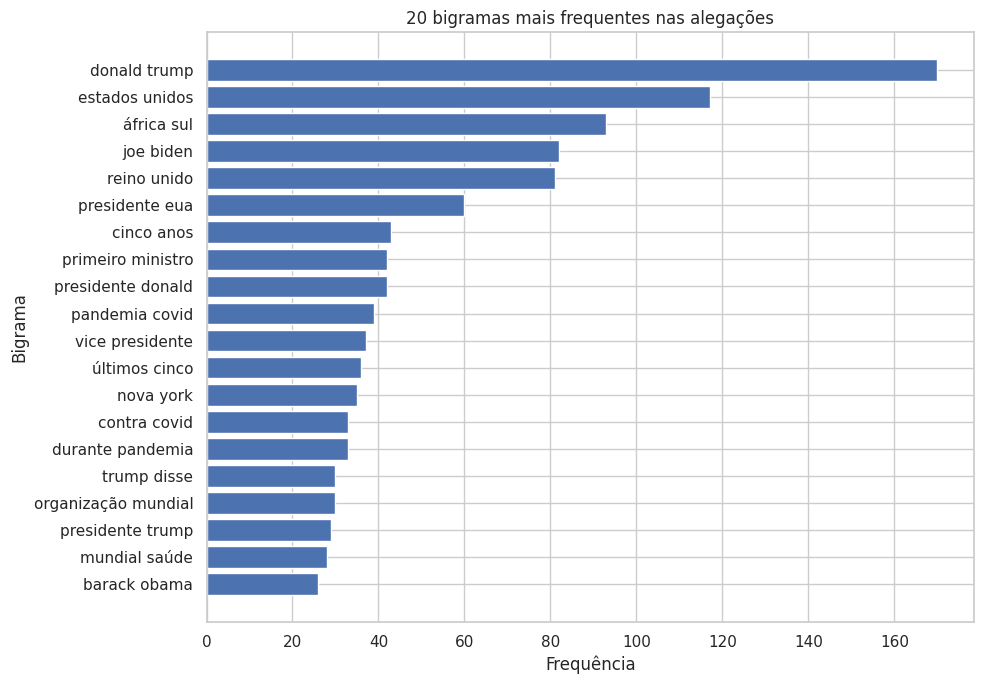

In [ ]:
# 20 bigramas mais frequentes

top20_bigramas = top30_bigramas.head(20).copy()
top20_bigramas_plot = top20_bigramas.sort_values("frequencia")

plt.figure(figsize=(10, 7))

plt.barh(
    top20_bigramas_plot["bigrama"],
    top20_bigramas_plot["frequencia"]
)

plt.title("20 bigramas mais frequentes nas alegações")
plt.xlabel("Frequência")
plt.ylabel("Bigrama")

plt.tight_layout()
plt.show()

## 12. Reconhecimento de Entidades Nomeadas (NER)

Além da análise de palavras e bigramas, será utilizado o Reconhecimento de Entidades Nomeadas (*Named Entity Recognition* — NER) para identificar entidades mencionadas nas alegações.

Essa análise permite observar a presença de pessoas, organizações, localidades e outras entidades reconhecidas automaticamente nos textos, complementando a análise lexical realizada anteriormente.

O reconhecimento será aplicado sobre as alegações originais, preservando o contexto linguístico necessário para a identificação das entidades.

Como o reconhecimento é realizado automaticamente por um modelo de linguagem, as classificações obtidas não serão consideradas anotações definitivas. Possíveis ambiguidades ou classificações inadequadas serão consideradas durante a interpretação dos resultados.

In [ ]:
# Instalação do modelo em português do spaCy

!python -m spacy download pt_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 89.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy

nlp = spacy.load("pt_core_news_sm")

print("Modelo carregado com sucesso!")

Modelo carregado com sucesso!


In [ ]:
# Reconhecimento de entidades nas alegações originais

entidades = []

for doc in nlp.pipe(
    claims_lexical_df["claim_original"].tolist(),
    batch_size=50
):
    for entidade in doc.ents:
        entidades.append({
            "entidade": entidade.text.strip(),
            "tipo": entidade.label_
        })

entidades_df = pd.DataFrame(entidades)

print("Total de entidades identificadas:", len(entidades_df))
print("Entidades distintas:", entidades_df["entidade"].nunique())

print("\nDistribuição por tipo:\n")

distribuicao_entidades = (
    entidades_df["tipo"]
    .value_counts()
)

display(distribuicao_entidades.to_frame("quantidade"))

Total de entidades identificadas: 6746
Entidades distintas: 2628

Distribuição por tipo:



,quantidade
tipo,
LOC,3445
PER,1560
ORG,881
MISC,860


### 12.1 Distribuição das entidades identificadas

O modelo de NER identificou **6.746 ocorrências de entidades nomeadas** nas 3.567 alegações analisadas, correspondendo a **2.628 formas textuais distintas**.

A categoria mais frequente foi `LOC`, com **3.445 ocorrências**, seguida por `PER`, com **1.560**, `ORG`, com **881**, e `MISC`, com **860 ocorrências**.

Esses valores representam ocorrências de entidades ao longo dos textos e não o número de alegações que contêm cada categoria. Uma mesma alegação pode apresentar múltiplas entidades, e uma mesma entidade pode aparecer em diferentes registros.

A predominância inicial de entidades classificadas como localização é compatível com a presença frequente de referências geográficas observada anteriormente na análise lexical e nos metadados. Entretanto, como as categorias foram atribuídas automaticamente pelo modelo, é necessário inspecionar as entidades classificadas em cada tipo antes de interpretar essa distribuição de forma mais detalhada.

### 12.2 Inspeção das entidades mais frequentes por categoria

Antes de interpretar os resultados do reconhecimento de entidades, serão inspecionadas as entidades mais frequentes em cada categoria atribuída pelo modelo.

Essa etapa permite verificar se as classificações automáticas são coerentes com o conteúdo das alegações e identificar possíveis ambiguidades ou erros de reconhecimento.

In [ ]:
# Entidades mais frequentes por categoria

for tipo in ["LOC", "PER", "ORG", "MISC"]:

    print(f"\n{'=' * 50}")
    print(f"20 entidades mais frequentes — {tipo}")
    print("=" * 50)

    top_entidades_tipo = (
        entidades_df.loc[
            entidades_df["tipo"] == tipo,
            "entidade"
        ]
        .value_counts()
        .head(20)
    )

    display(top_entidades_tipo.to_frame("quantidade"))


20 entidades mais frequentes — LOC


,quantidade
entidade,
EUA,365
COVID-19,197
Nigéria,168
Quênia,129
Estados Unidos,107
Índia,99
África do Sul,88
Covid-19,88
China,83



20 entidades mais frequentes — PER


,quantidade
entidade,
Donald Trump,150
Joe Biden,80
Barack Obama,24
Presidente Trump,17
Presidente Donald Trump,16
Kamala Harris,16
Bernie Sanders,15
Trump,14
Nancy Pelosi,13



20 entidades mais frequentes — ORG


,quantidade
entidade,
OMS,29
Organização Mundial da Saúde,28
Covid-19,25
UE,22
CDC,16
COVID-19,14
BJP,13
FBI,12
Partido Democrata,12



20 entidades mais frequentes — MISC


,quantidade
entidade,
Presidente,44
”,25
Facebook,22
Presidente dos,18
Trump,17
US$,14
G,12
Twitter,10
Senado,9


#### Resultado da inspeção das entidades

A inspeção das entidades mais frequentes mostra que o modelo de NER consegue identificar diversas entidades coerentes com as categorias atribuídas, mas também apresenta erros e ambiguidades relevantes.

Na categoria `LOC`, aparecem corretamente diversas referências geográficas, como `EUA`, `Nigéria`, `Quênia`, `Estados Unidos`, `Índia`, `África do Sul`, `China` e `Reino Unido`. Entretanto, também foram classificados como localização termos como `COVID-19`, `Trump`, `Biden`, `coronavírus`, `US$` e `Congresso`, indicando erros de classificação.

Na categoria `PER`, predominam nomes de pessoas, como `Donald Trump`, `Joe Biden`, `Barack Obama`, `Kamala Harris`, `Bernie Sanders` e `Hillary Clinton`. Ainda assim, também foram observadas classificações inadequadas, como `Brexit`. Além disso, uma mesma pessoa pode aparecer representada de diferentes formas, como `Donald Trump`, `Presidente Trump`, `Presidente Donald Trump` e `Trump`, fragmentando suas frequências.

Na categoria `ORG`, foram reconhecidas organizações como `OMS`, `Organização Mundial da Saúde`, `CDC`, `FBI`, `Banco Mundial`, `BBC` e `NASA`. Porém, termos como `COVID-19`, `Covid-19`, `US$` e `AVC` também aparecem nessa categoria, mostrando novamente limitações do reconhecimento automático.

A categoria `MISC` apresenta maior heterogeneidade, reunindo entidades e expressões como `Facebook`, `Twitter`, `WhatsApp`, `ISIS`, `5G` e `Lei de Cuidados Acessíveis`, mas também fragmentos pouco informativos ou incorretamente reconhecidos, incluindo sinais de aspas e termos isolados.

Dessa forma, os resultados do NER são úteis para indicar a presença recorrente de pessoas, localidades e organizações nas alegações, mas suas contagens não devem ser interpretadas como classificações exatas. O modelo apresenta erros de categorização, fragmentação e variações na representação das entidades, sendo necessária cautela na utilização dessas informações em etapas posteriores.

## 13. Síntese da análise exploratória

A análise exploratória do AVERITEC-BR permitiu compreender a estrutura das alegações, a distribuição das classes, a qualidade dos dados, as características textuais, os metadados e, principalmente, a organização das evidências utilizadas no processo de verificação.


### 13.1 Principais achados

Os arquivos analisados correspondem às partições de treino e desenvolvimento e totalizam **3.568 registros**, sendo **3.068 no conjunto de treino** e **500 no conjunto de desenvolvimento**.

O dataset apresenta quatro classes de veracidade. A distribuição não é balanceada: `Refuted` é a classe predominante, representando aproximadamente **57% do treino e 61% do desenvolvimento**, seguida por `Supported`. As classes `Not Enough Evidence` e `Conflicting Evidence/Cherrypicking` possuem representação consideravelmente menor.

Em relação ao conteúdo textual, as alegações são relativamente curtas. No conjunto de treino, a mediana é de **17 palavras**, e 50% dos textos possuem entre **13 e 23 palavras**. Foram identificadas **113 alegações acima do limite superior definido pelo critério do IQR**, mas a inspeção dos casos mais extensos não revelou problemas estruturais evidentes.

A comparação do comprimento das alegações entre as classes mostrou **forte sobreposição entre suas distribuições**. Embora existam pequenas diferenças nas medidas centrais, não foi observada uma separação evidente dos rótulos com base apenas no número de palavras. Também foram identificadas alegações de comprimento atípico em diferentes classes, reforçando que textos mais extensos não representam, isoladamente, erros ou anomalias.

A análise lexical revelou recorrência de referências políticas, geográficas e relacionadas à saúde pública. Entre os termos mais frequentes aparecem `não`, `eua`, `covid`, `trump`, `presidente`, `coronavírus`, `governo`, `nigéria` e `biden`. Os bigramas reforçam esses padrões, com combinações como `donald trump`, `estados unidos`, `áfrica sul`, `joe biden`, `reino unido` e `pandemia covid`.

Um dos principais diferenciais estruturais do conjunto é a presença de evidências organizadas em perguntas e respostas. As alegações possuem, em geral, duas perguntas e duas respostas associadas, embora existam casos com estruturas de evidência mais extensas. Foram analisadas **9.878 respostas**, classificadas como `Extractive`, `Abstractive`, `Boolean` ou `Unanswerable`.

As respostas `Extractive` são predominantes, correspondendo a pouco mais da metade das evidências. A classe `Not Enough Evidence` apresenta uma característica particularmente relevante: **24,89% de suas respostas são `Unanswerable`**, proporção substancialmente superior à observada nas demais classes.

Também foram observadas diferenças na extensão das evidências entre as classes. `Conflicting Evidence/Cherrypicking` apresenta, em média, maior número de perguntas e respostas por alegação do que as demais categorias.

As fontes utilizadas como evidência são predominantemente conteúdos textuais da web, mas o conjunto também contém PDFs, tabelas, imagens, vídeos, áudios e metadados. Após a recuperação dos domínios originais presentes em URLs arquivadas, foram identificados **2.453 domínios distintos**, evidenciando grande diversidade de fontes utilizadas no processo de verificação.

Os metadados também mostram diversidade na composição do dataset. A maior parte das classificações de `claim_types` corresponde a `Event/Property Claim` e `Numerical Claim`, enquanto `Written Evidence` é a estratégia de checagem mais frequente. Aproximadamente **42,91% das alegações** estão associadas a mais de uma estratégia de verificação.

Geograficamente, foram identificados **70 códigos de localização distintos** entre os registros com essa informação disponível. Entretanto, a distribuição não é uniforme, com forte concentração nos Estados Unidos e participação relevante de países como Índia, Reino Unido, Nigéria, Quênia e África do Sul.

A análise de `reporting_source` mostrou ainda uma presença expressiva de plataformas digitais entre as origens ou contextos de publicação registrados. Dos **3.568 registros**, **2.863** possuem essa informação preenchida. Após uma normalização conservadora de capitalização e espaços, foram identificadas **609 formas distintas**, com destaque para `facebook` (987 registros), `twitter` (403) e `youtube` (86).

Além das redes sociais, o campo contém veículos jornalísticos, discursos, coletivas de imprensa, reuniões e outros contextos de declaração. Portanto, `reporting_source` não representa uma taxonomia uniforme de plataformas, mas fornece informações relevantes sobre os diferentes ambientes associados à circulação das alegações.

### 13.2 Qualidade e limitações dos dados

Os campos centrais para a análise — como `label`, `justification`, `questions`, `claim_types` e `fact_checking_strategies` — apresentam elevada completude. As principais ausências estão concentradas em metadados, especialmente `speaker`, `original_claim_url`, `reporting_source` e `cached_original_claim_url`.

Foi identificado apenas um registro sem conteúdo em `claim`. Como esse registro ainda possui rótulo, justificativa, evidências e outros metadados, ele foi preservado nas análises estruturais e excluído apenas das etapas dependentes do texto da alegação.

Não foram encontradas duplicações completas de registros. Entretanto, existem alegações textualmente repetidas, inclusive alguns casos associados a diferentes rótulos ou contextos. Também foram identificadas **sete alegações textualmente idênticas presentes tanto no conjunto de treino quanto no conjunto de desenvolvimento**. Essa característica deve ser considerada em futuras etapas de avaliação, especialmente em abordagens baseadas exclusivamente no texto da alegação.

Outro aspecto relevante é o campo `required_reannotation`. Aproximadamente um quarto dos registros está sinalizado para reanotação, com maior proporção nas classes `Conflicting Evidence/Cherrypicking` e `Not Enough Evidence`. Essa sinalização não foi interpretada automaticamente como erro, mas representa uma informação importante sobre a qualidade e estabilidade das anotações.

A estrutura interna das evidências apresenta elevada completude. As ausências observadas estão, em grande parte, relacionadas ao funcionamento esperado de cada `answer_type`. Foram encontrados apenas dois casos isolados de ausência inesperada em campos principais das respostas.

O campo `speaker` apresenta algumas inconsistências de representação, incluindo diferenças de capitalização e utilização de títulos ou cargos. Uma normalização conservadora reduziu o número de valores distintos de 1.536 para 1.519, mas formas semanticamente semelhantes não foram agrupadas automaticamente.

Por fim, o reconhecimento automático de entidades nomeadas apresentou erros de categorização e fragmentação. Embora tenha identificado corretamente diversas pessoas, organizações e localidades, também classificou termos como `COVID-19`, `Trump`, `Biden` e `US$` em categorias inadequadas. Dessa forma, os resultados de NER devem ser utilizados como indicadores exploratórios e não como anotações definitivas.

### 13.3 Implicações para o projeto FOMO

Os resultados da análise exploratória indicam que o AVERITEC-BR possui características relevantes para as próximas etapas do projeto FOMO, especialmente por combinar alegações, rótulos, metadados e evidências estruturadas em perguntas e respostas.

O **desbalanceamento entre as classes** deverá ser considerado em futuras etapas de modelagem e avaliação. Como `Refuted` representa a maior parte dos registros, métricas globais podem não refletir adequadamente o desempenho nas classes menos frequentes, como `Not Enough Evidence` e `Conflicting Evidence/Cherrypicking`.

A forte sobreposição observada no comprimento das alegações entre as classes também indica que características superficiais do texto, como o número de palavras, **não apresentam isoladamente uma separação evidente entre os rótulos**.

A estrutura de evidências constitui uma característica particularmente relevante para o projeto. Uma mesma alegação pode estar associada a múltiplas perguntas e respostas, e essas respostas podem assumir diferentes formatos. Dessa forma, futuras abordagens poderão considerar não apenas o texto da alegação, mas também as evidências e justificativas associadas ao processo de verificação.

A diversidade de fontes e domínios identificada também representa uma oportunidade para analisar a origem das evidências. Entretanto, a ausência parcial e a heterogeneidade de alguns metadados indicam que informações como `speaker`, `reporting_source`, localização e URLs não devem ser tratadas como universalmente disponíveis.

As alegações repetidas entre treino e desenvolvimento também deverão ser consideradas na definição de futuras estratégias de separação e avaliação dos dados, especialmente caso sejam utilizados modelos fortemente dependentes da similaridade textual.

Por fim, campos como `required_reannotation` e os casos de evidência `Unanswerable` fornecem informações adicionais sobre situações de maior incerteza ou dificuldade de verificação, podendo ser relevantes para o desenvolvimento de uma ferramenta que apresente evidências e incertezas ao usuário em vez de depender exclusivamente de uma classificação final.

### 13.4 Próximos passos

A partir dos resultados desta análise exploratória, as próximas etapas deverão considerar as características identificadas no AVERITEC-BR durante a organização e preparação dos dados para o projeto FOMO.

A análise exploratória do AVeriTeC original complementa a compreensão do conjunto em sua versão original em inglês, enquanto os resultados obtidos no LIAR-BR permitem observar uma estrutura alternativa de dados voltados à verificação de alegações.

Com as análises exploratórias dos conjuntos selecionados, será possível avançar para a **definição do esquema de dados do projeto**, considerando quais campos e estruturas são relevantes para representar alegações, evidências, fontes, classificações e demais informações necessárias ao funcionamento da solução.

Em etapas posteriores, também deverão ser definidos os critérios de preparação e separação dos dados para **treino, validação e teste**, levando em consideração aspectos identificados durante a EDA, como desbalanceamento das classes, alegações repetidas, disponibilidade de metadados e diversidade das estruturas de evidência.

Posteriormente, a avaliação dos modelos deverá considerar não apenas métricas globais de desempenho, mas também o comportamento entre as diferentes classes e a calibração das estimativas produzidas, de forma compatível com os objetivos definidos para o projeto FOMO.